In [1]:
import sys, platform, time, warnings
import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt
import sklearn, scipy
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 140)

print("Python      :", platform.python_version())
for lib in (np, pd, sklearn, scipy, matplotlib):
    print(f"{lib.__name__:<12}:", lib.__version__)

Python      : 3.13.5
numpy       : 2.3.4
pandas      : 3.0.2
sklearn     : 1.8.0
scipy       : 1.17.1
matplotlib  : 3.10.8


In [2]:
df_raw = pd.read_csv("dataset/CC GENERAL.csv")
print("Dimensiones:", df_raw.shape)
print("IDs únicos (CUST_ID):", df_raw["CUST_ID"].nunique())
print("Filas duplicadas (sin ID):", df_raw.drop(columns="CUST_ID").duplicated().sum())

resumen = pd.DataFrame({"tipo": df_raw.dtypes.astype(str),
                        "valores_unicos": df_raw.nunique(),
                        "nulos": df_raw.isna().sum(),
                        "%_nulos": (100 * df_raw.isna().mean()).round(2)})
print(resumen)

Dimensiones: (8950, 18)
IDs únicos (CUST_ID): 8950
Filas duplicadas (sin ID): 0
                                     tipo  valores_unicos  nulos  %_nulos
CUST_ID                               str            8950      0     0.00
BALANCE                           float64            8871      0     0.00
BALANCE_FREQUENCY                 float64              43      0     0.00
PURCHASES                         float64            6203      0     0.00
ONEOFF_PURCHASES                  float64            4014      0     0.00
INSTALLMENTS_PURCHASES            float64            4452      0     0.00
CASH_ADVANCE                      float64            4323      0     0.00
PURCHASES_FREQUENCY               float64              47      0     0.00
ONEOFF_PURCHASES_FREQUENCY        float64              47      0     0.00
PURCHASES_INSTALLMENTS_FREQUENCY  float64              47      0     0.00
CASH_ADVANCE_FREQUENCY            float64              54      0     0.00
CASH_ADVANCE_TRX                

In [3]:
df = df_raw.drop(columns="CUST_ID")   # identificador: no describe comportamiento

# Frecuencias y proporciones deberían estar entre 0 y 1
frec = [c for c in df.columns if c.endswith("FREQUENCY") or c == "PRC_FULL_PAYMENT"]
fuera = {c: int(((df[c] < 0) | (df[c] > 1)).sum()) for c in frec}
print("Variables de frecuencia/proporción fuera de [0, 1]:", fuera)
print("Valores negativos por variable:",
      {c: int((df[c] < 0).sum()) for c in df.columns if (df[c] < 0).any()} or "ninguno")

# Redundancia: el total de compras debería ser la suma de sus dos tipos
dif = (df["PURCHASES"] - df["ONEOFF_PURCHASES"] - df["INSTALLMENTS_PURCHASES"]).abs()
print("PURCHASES = ONEOFF + INSTALLMENTS (dif. ≤ 1):", f"{(dif <= 1).mean():.1%} de las filas")

print("Clientes con MINIMUM_PAYMENTS > PAYMENTS:", int((df["MINIMUM_PAYMENTS"] > df["PAYMENTS"]).sum()))
print("Filas con algún nulo:", int(df.isna().any(axis=1).sum()))
print("\nDistribución de TENURE (meses como cliente):")
print(df["TENURE"].value_counts().sort_index())

Variables de frecuencia/proporción fuera de [0, 1]: {'BALANCE_FREQUENCY': 0, 'PURCHASES_FREQUENCY': 0, 'ONEOFF_PURCHASES_FREQUENCY': 0, 'PURCHASES_INSTALLMENTS_FREQUENCY': 0, 'CASH_ADVANCE_FREQUENCY': 8, 'PRC_FULL_PAYMENT': 0}
Valores negativos por variable: ninguno
PURCHASES = ONEOFF + INSTALLMENTS (dif. ≤ 1): 99.8% de las filas
Clientes con MINIMUM_PAYMENTS > PAYMENTS: 2365
Filas con algún nulo: 314

Distribución de TENURE (meses como cliente):
TENURE
6      204
7      190
8      196
9      175
10     236
11     365
12    7584
Name: count, dtype: int64


In [4]:
import os
os.makedirs("figuras", exist_ok=True)

desc = df.describe().T[["mean", "std", "min", "50%", "max"]]
desc.columns = ["Media", "Desv. Est.", "Mín.", "Mediana", "Máx."]
desc["Asimetría"] = df.skew()
desc["% ceros"] = 100 * (df == 0).mean()
print(desc.round(2).to_string())

# ¿Los nulos de MINIMUM_PAYMENTS coinciden con clientes que no pagaron nada?
print("\nNulos de MINIMUM_PAYMENTS según PAYMENTS = 0:")
print(pd.crosstab(df["MINIMUM_PAYMENTS"].isna(), df["PAYMENTS"] == 0,
                  rownames=["MIN_PAY nulo"], colnames=["PAYMENTS = 0"]))

                                    Media  Desv. Est.   Mín.  Mediana      Máx.  Asimetría  % ceros
BALANCE                           1564.47     2081.53   0.00   873.39  19043.14       2.39     0.89
BALANCE_FREQUENCY                    0.88        0.24   0.00     1.00      1.00      -2.02     0.89
PURCHASES                         1003.20     2136.63   0.00   361.28  49039.57       8.14    22.84
ONEOFF_PURCHASES                   592.44     1659.89   0.00    38.00  40761.25      10.05    48.07
INSTALLMENTS_PURCHASES             411.07      904.34   0.00    89.00  22500.00       7.30    43.75
CASH_ADVANCE                       978.87     2097.16   0.00     0.00  47137.21       5.17    51.71
PURCHASES_FREQUENCY                  0.49        0.40   0.00     0.50      1.00       0.06    22.83
ONEOFF_PURCHASES_FREQUENCY           0.20        0.30   0.00     0.08      1.00       1.54    48.07
PURCHASES_INSTALLMENTS_FREQUENCY     0.36        0.40   0.00     0.17      1.00       0.51    43.74


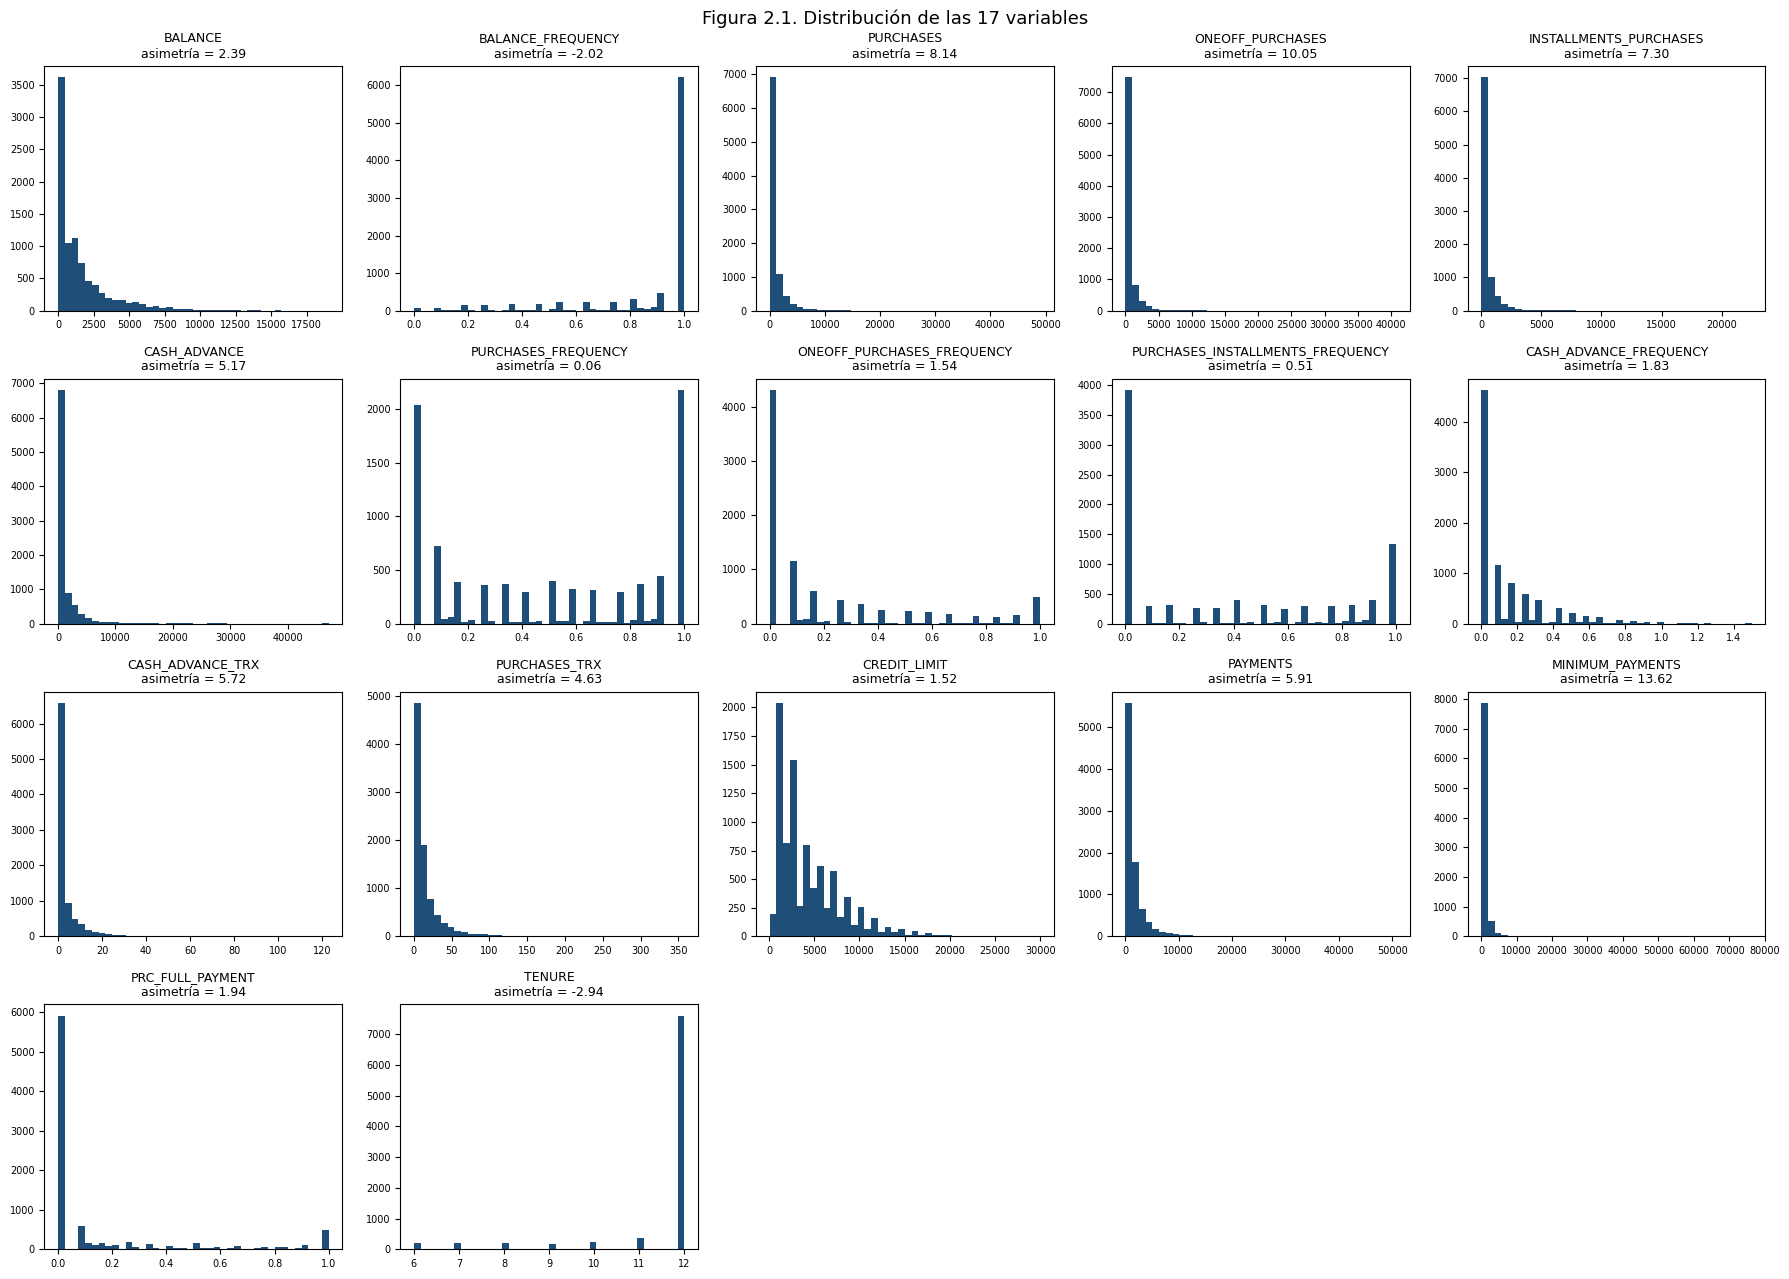

In [5]:
fig, axes = plt.subplots(4, 5, figsize=(18, 13))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col].dropna(), bins=40, color="#1f4e79")
    ax.set_title(f"{col}\nasimetría = {df[col].skew():.2f}", fontsize=9)
    ax.tick_params(labelsize=7)
for ax in axes.ravel()[len(df.columns):]:
    ax.axis("off")
fig.suptitle("Figura 2.1. Distribución de las 17 variables", fontsize=13)
plt.tight_layout(); plt.savefig("figuras/fig_2_1_histogramas.png", dpi=150); plt.show()

                                  atípicos      %
BALANCE_FREQUENCY                     1493  16.68
PRC_FULL_PAYMENT                      1474  16.47
TENURE                                1366  15.26
CASH_ADVANCE                          1030  11.51
ONEOFF_PURCHASES                      1013  11.32
INSTALLMENTS_PURCHASES                 867   9.69
MINIMUM_PAYMENTS                       841   9.40
PAYMENTS                               808   9.03
PURCHASES                              808   9.03
CASH_ADVANCE_TRX                       804   8.98
ONEOFF_PURCHASES_FREQUENCY             782   8.74
PURCHASES_TRX                          766   8.56
BALANCE                                695   7.77
CASH_ADVANCE_FREQUENCY                 525   5.87
CREDIT_LIMIT                           248   2.77
PURCHASES_INSTALLMENTS_FREQUENCY         0   0.00
PURCHASES_FREQUENCY                      0   0.00

Clientes con al menos un atípico: 5956 (66.5 %)


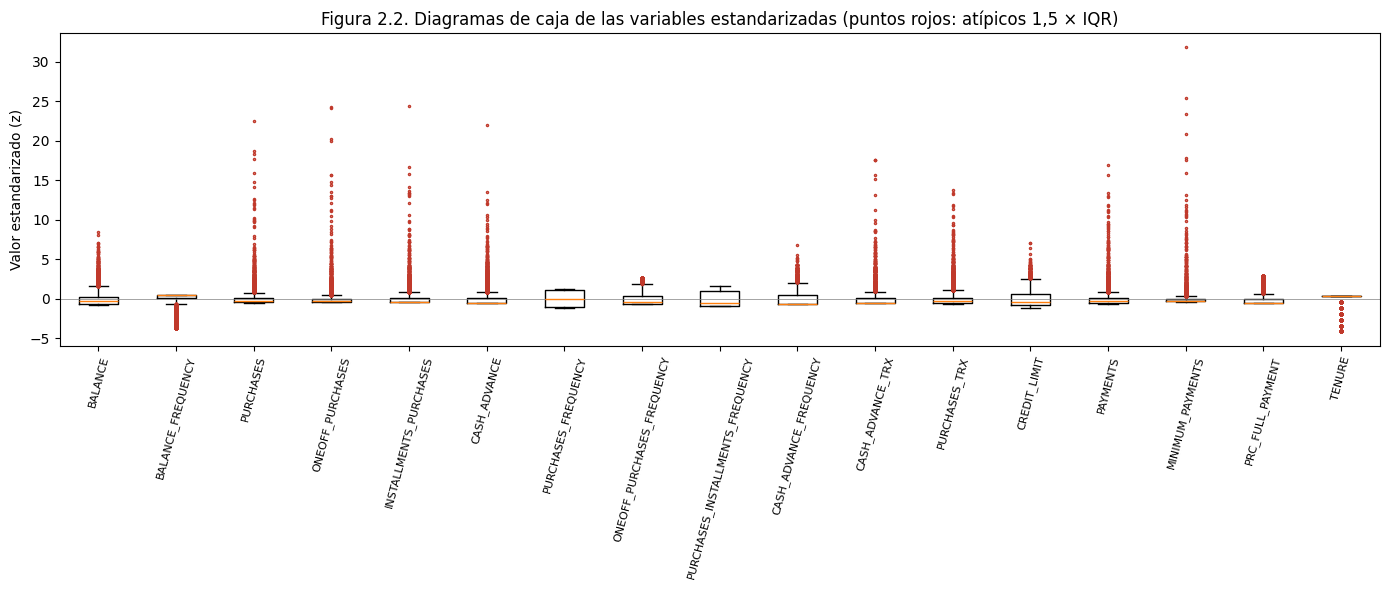

In [6]:
Q1, Q3 = df.quantile(0.25), df.quantile(0.75)
IQR = Q3 - Q1
mask_atip = (df < Q1 - 1.5 * IQR) | (df > Q3 + 1.5 * IQR)
atip = pd.DataFrame({"atípicos": mask_atip.sum(), "%": (100 * mask_atip.mean()).round(2)})
print(atip.sort_values("atípicos", ascending=False).to_string())
print(f"\nClientes con al menos un atípico: {mask_atip.any(axis=1).sum()} "
      f"({100 * mask_atip.any(axis=1).mean():.1f} %)")

z = (df - df.mean()) / df.std()          # solo para graficar en una misma escala
fig, ax = plt.subplots(figsize=(14, 6))
ax.boxplot([z[c].dropna() for c in df.columns], whis=1.5,
           flierprops=dict(marker=".", markersize=3, markeredgecolor="#c0392b"))
ax.set_xticks(range(1, len(df.columns) + 1)); ax.set_xticklabels(df.columns, rotation=75, fontsize=8)
ax.set_ylabel("Valor estandarizado (z)"); ax.axhline(0, color="grey", lw=0.5)
ax.set_title("Figura 2.2. Diagramas de caja de las variables estandarizadas (puntos rojos: atípicos 1,5 × IQR)")
plt.tight_layout(); plt.savefig("figuras/fig_2_2_boxplots.png", dpi=150); plt.show()

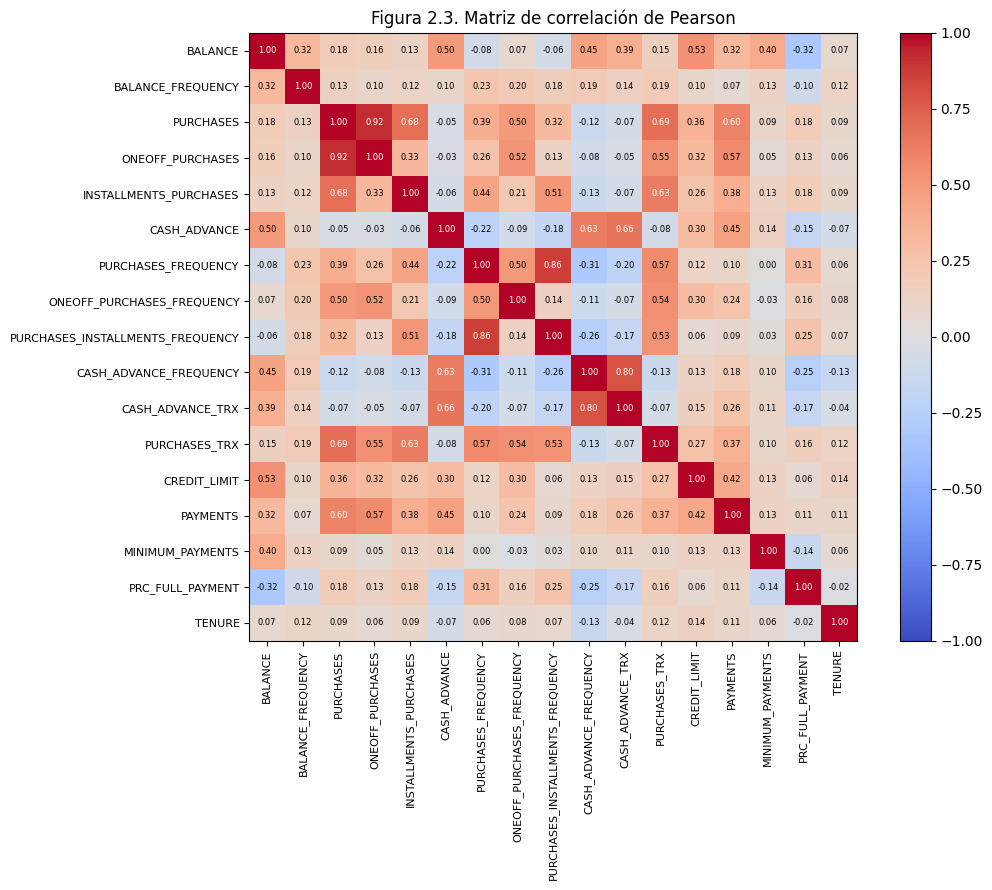

                                                         pearson  spearman
PURCHASES              ONEOFF_PURCHASES                    0.917     0.751
PURCHASES_FREQUENCY    PURCHASES_INSTALLMENTS_FREQUENCY    0.863     0.852
CASH_ADVANCE_FREQUENCY CASH_ADVANCE_TRX                    0.800     0.983
PURCHASES              PURCHASES_TRX                       0.690     0.885
                       INSTALLMENTS_PURCHASES              0.680     0.706
CASH_ADVANCE           CASH_ADVANCE_TRX                    0.656     0.952
                       CASH_ADVANCE_FREQUENCY              0.629     0.941
INSTALLMENTS_PURCHASES PURCHASES_TRX                       0.628     0.784
PURCHASES              PAYMENTS                            0.603     0.395
PURCHASES_FREQUENCY    PURCHASES_TRX                       0.568     0.924

Pares con |r| ≥ 0,7 (Pearson): 3


In [7]:
corr = df.corr(method="pearson")
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, fraction=0.046); ax.set_title("Figura 2.3. Matriz de correlación de Pearson")
plt.tight_layout(); plt.savefig("figuras/fig_2_3_correlacion.png", dpi=150); plt.show()

# Pares más correlacionados (Pearson y Spearman, que es menos sensible a la asimetría)
spear = df.corr(method="spearman")
sup = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pares = pd.DataFrame({"pearson": corr.where(sup).stack(), "spearman": spear.where(sup).stack()})
pares = pares.reindex(pares["pearson"].abs().sort_values(ascending=False).index)
print(pares.head(10).round(3).to_string())
print("\nPares con |r| ≥ 0,7 (Pearson):", int((pares["pearson"].abs() >= 0.7).sum()))

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_tr_raw, X_te_raw = train_test_split(df, test_size=0.30, random_state=SEED)
print("Entrenamiento:", X_tr_raw.shape, "| Prueba:", X_te_raw.shape)

Entrenamiento: (6265, 17) | Prueba: (2685, 17)


In [9]:
# Variables de montos y de número de transacciones (muy asimétricas): se transforman con log(1 + x)
VARS_LOG = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
            "CASH_ADVANCE_TRX", "PURCHASES_TRX", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS"]

# Valores de imputación aprendidos SOLO con el entrenamiento
med_min_pay = X_tr_raw.loc[X_tr_raw["PAYMENTS"] > 0, "MINIMUM_PAYMENTS"].median()
med_limit = X_tr_raw["CREDIT_LIMIT"].median()
print(f"Mediana de MINIMUM_PAYMENTS (clientes con pagos, train): {med_min_pay:.2f}")
print(f"Mediana de CREDIT_LIMIT (train): {med_limit:.2f}")

def limpiar(X):
    """Reglas de limpieza: usan solo valores fijos o aprendidos en el entrenamiento."""
    X = X.copy()
    X["CASH_ADVANCE_FREQUENCY"] = X["CASH_ADVANCE_FREQUENCY"].clip(upper=1)        # puntaje acotado a [0, 1]
    sin_pago = X["MINIMUM_PAYMENTS"].isna() & (X["PAYMENTS"] == 0)
    X.loc[sin_pago, "MINIMUM_PAYMENTS"] = 0                                          # no pagó nada
    X["MINIMUM_PAYMENTS"] = X["MINIMUM_PAYMENTS"].fillna(med_min_pay)               # resto de nulos
    X["CREDIT_LIMIT"] = X["CREDIT_LIMIT"].fillna(med_limit)
    return X

X_tr_imp, X_te_imp = limpiar(X_tr_raw), limpiar(X_te_raw)    # unidades originales (para interpretar)
for nombre, X in [("train", X_tr_raw), ("test", X_te_raw)]:
    print(f"{nombre}: MIN_PAY nulos = {X['MINIMUM_PAYMENTS'].isna().sum()} "
          f"(con PAYMENTS = 0: {(X['MINIMUM_PAYMENTS'].isna() & (X['PAYMENTS'] == 0)).sum()}), "
          f"CREDIT_LIMIT nulos = {X['CREDIT_LIMIT'].isna().sum()}, "
          f"CASH_ADV_FREQ > 1 = {(X['CASH_ADVANCE_FREQUENCY'] > 1).sum()}")
print("Nulos después de limpiar:", int(X_tr_imp.isna().sum().sum()), "/", int(X_te_imp.isna().sum().sum()))

# Transformación logarítmica (regla fija, no aprende de los datos)
X_tr_log, X_te_log = X_tr_imp.copy(), X_te_imp.copy()
X_tr_log[VARS_LOG] = np.log1p(X_tr_log[VARS_LOG])
X_te_log[VARS_LOG] = np.log1p(X_te_log[VARS_LOG])

# Escalado: el StandardScaler se ajusta SOLO con el entrenamiento
scaler = StandardScaler().fit(X_tr_log)
Xs_tr = scaler.transform(X_tr_log)
Xs_te = scaler.transform(X_te_log)
print("\nMedia y desv. de Xs_tr (deben ser 0 y 1):", Xs_tr.mean().round(3), Xs_tr.std().round(3))
print("Media y desv. de Xs_te (cercanas, no exactas):", Xs_te.mean().round(3), Xs_te.std().round(3))

asim = pd.DataFrame({"antes (train)": X_tr_imp[VARS_LOG].skew(),
                     "después de log (train)": X_tr_log[VARS_LOG].skew()}).round(2)
print("\nAsimetría de las variables transformadas:")
print(asim.to_string())

Mediana de MINIMUM_PAYMENTS (clientes con pagos, train): 311.09
Mediana de CREDIT_LIMIT (train): 3000.00
train: MIN_PAY nulos = 233 (con PAYMENTS = 0: 181), CREDIT_LIMIT nulos = 1, CASH_ADV_FREQ > 1 = 5
test: MIN_PAY nulos = 80 (con PAYMENTS = 0: 59), CREDIT_LIMIT nulos = 0, CASH_ADV_FREQ > 1 = 3
Nulos después de limpiar: 0 / 0

Media y desv. de Xs_tr (deben ser 0 y 1): 0.0 1.0
Media y desv. de Xs_te (cercanas, no exactas): 0.003 0.989

Asimetría de las variables transformadas:
                        antes (train)  después de log (train)
BALANCE                          2.41                   -0.85
PURCHASES                        7.95                   -0.76
ONEOFF_PURCHASES                 9.91                    0.19
INSTALLMENTS_PURCHASES           6.23                   -0.03
CASH_ADVANCE                     5.57                    0.26
CASH_ADVANCE_TRX                 6.13                    0.96
PURCHASES_TRX                    4.76                    0.03
CREDIT_LIMIT         

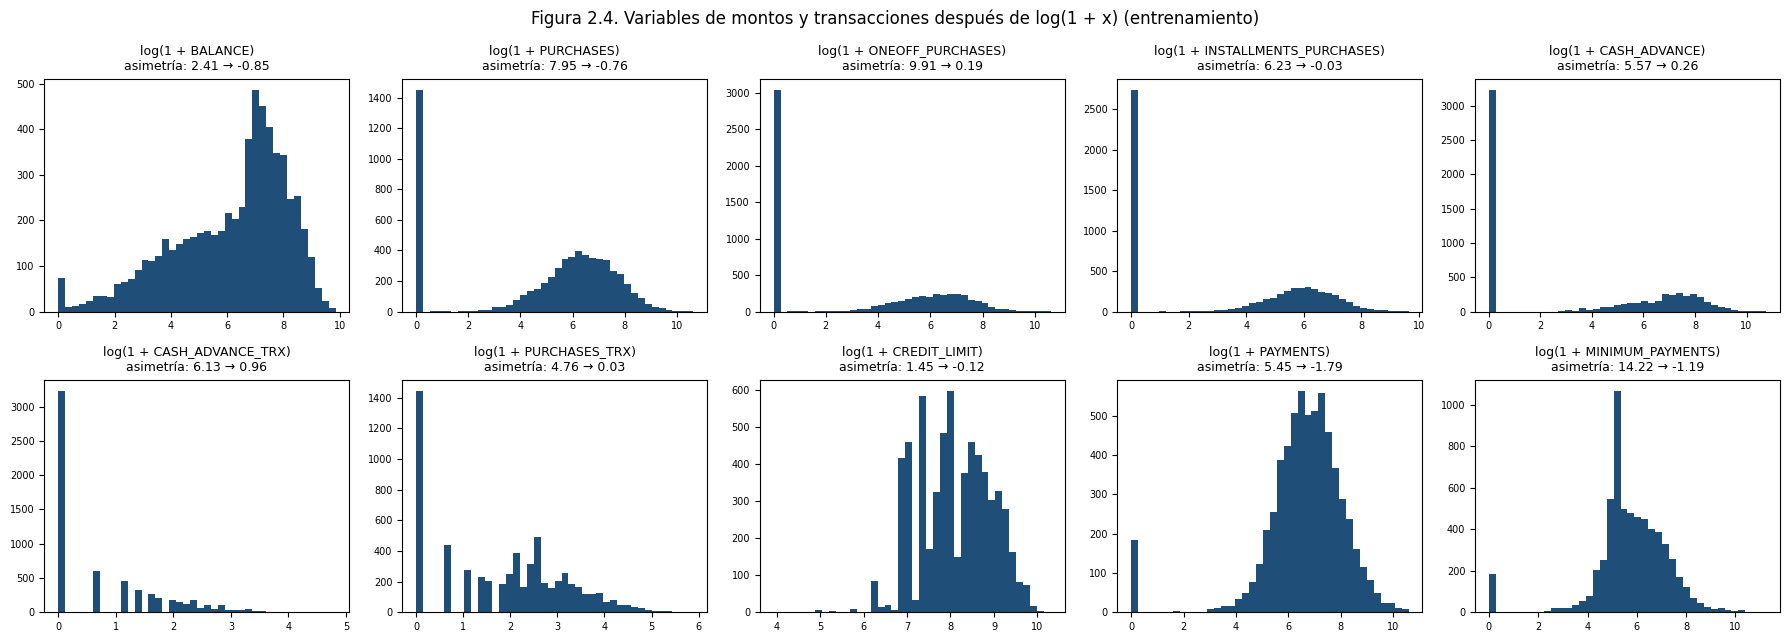

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5))
for ax, col in zip(axes.ravel(), VARS_LOG):
    ax.hist(X_tr_log[col], bins=40, color="#1f4e79")
    ax.set_title(f"log(1 + {col})\nasimetría: {asim.loc[col, 'antes (train)']} → "
                 f"{asim.loc[col, 'después de log (train)']}", fontsize=9)
    ax.tick_params(labelsize=7)
fig.suptitle("Figura 2.4. Variables de montos y transacciones después de log(1 + x) (entrenamiento)", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig_2_4_log.png", dpi=150); plt.show()

      inercia  silhouette  davies_bouldin  calinski_harabasz  grupo_min_%  tiempo_s  caída_inercia_%
k                                                                                                   
2   79121.687       0.256           1.490           2167.569       35.291     5.227              NaN
3   66887.555       0.227           1.683           1854.489       31.923     0.078           15.462
4   60157.642       0.222           1.674           1607.894       16.887     0.080           10.062
5   54381.734       0.219           1.579           1500.008       15.467     0.081            9.601
6   49829.434       0.222           1.449           1423.786       10.136     0.154            8.371
7   46691.775       0.226           1.416           1336.107        2.953     0.131            6.297
8   44241.914       0.228           1.370           1257.955        2.921     0.111            5.247
9   42085.541       0.218           1.434           1196.991        2.921     0.119        

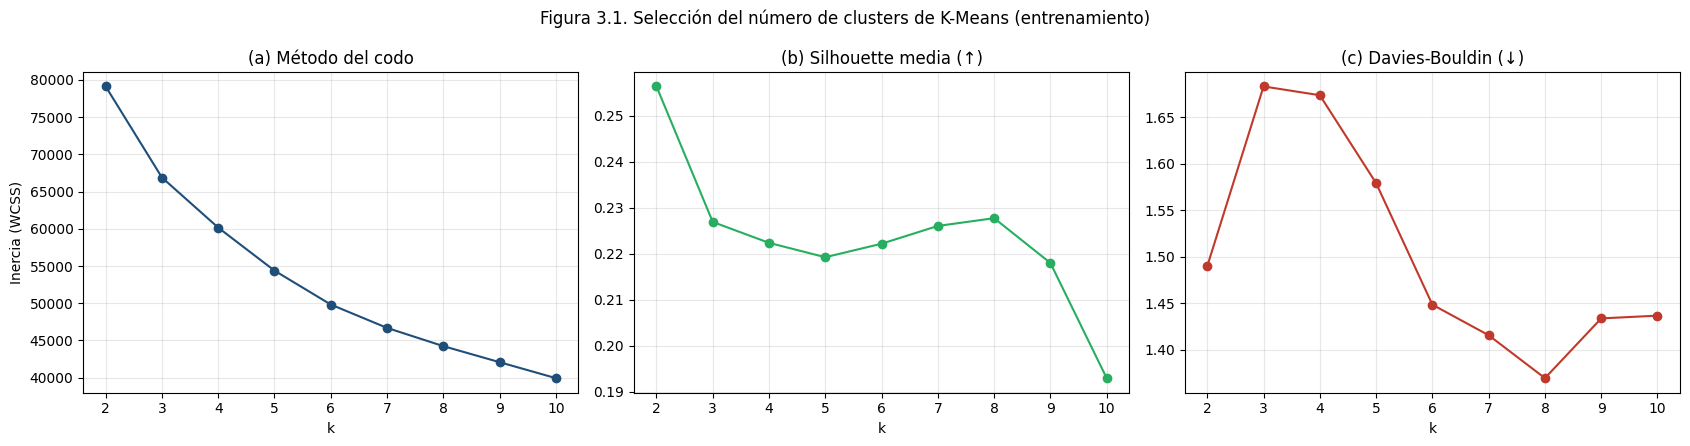

In [11]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

filas = []
for k in range(2, 11):
    t0 = time.perf_counter()
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Xs_tr)
    t = time.perf_counter() - t0
    lab = km.labels_
    filas.append({"k": k, "inercia": km.inertia_,
                  "silhouette": silhouette_score(Xs_tr, lab),
                  "davies_bouldin": davies_bouldin_score(Xs_tr, lab),
                  "calinski_harabasz": calinski_harabasz_score(Xs_tr, lab),
                  "grupo_min_%": 100 * np.bincount(lab).min() / len(lab),
                  "tiempo_s": t})
sel_k = pd.DataFrame(filas).set_index("k")
sel_k["caída_inercia_%"] = -100 * sel_k["inercia"].pct_change()
print(sel_k.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(sel_k.index, sel_k["inercia"], "o-", color="#1f4e79")
ax[0].set_title("(a) Método del codo"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inercia (WCSS)")
ax[1].plot(sel_k.index, sel_k["silhouette"], "o-", color="#27ae60")
ax[1].set_title("(b) Silhouette media (↑)"); ax[1].set_xlabel("k")
ax[2].plot(sel_k.index, sel_k["davies_bouldin"], "o-", color="#c0392b")
ax[2].set_title("(c) Davies-Bouldin (↓)"); ax[2].set_xlabel("k")
for a in ax: a.grid(alpha=0.3); a.set_xticks(sel_k.index)
fig.suptitle("Figura 3.1. Selección del número de clusters de K-Means (entrenamiento)", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig_3_1_seleccion_k.png", dpi=150); plt.show()

In [12]:
from sklearn.metrics import adjusted_rand_score

estab = []
for k in range(2, 9):
    ref = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs_tr)
    # (a) distintas semillas, una sola inicialización cada una
    ari_sem = [adjusted_rand_score(ref.labels_, KMeans(n_clusters=k, n_init=1, random_state=s).fit(Xs_tr).labels_)
               for s in range(10)]
    # (b) submuestras del 80 % del entrenamiento: se reentrena y se compara la asignación de todo el entrenamiento
    rng = np.random.RandomState(SEED)
    ari_sub = []
    for b in range(10):
        idx = rng.choice(len(Xs_tr), int(0.8 * len(Xs_tr)), replace=False)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Xs_tr[idx])
        ari_sub.append(adjusted_rand_score(ref.labels_, km_b.predict(Xs_tr)))
    tam = np.sort(np.bincount(ref.labels_))[::-1] / len(Xs_tr) * 100
    estab.append({"k": k, "ARI_semillas_media": np.mean(ari_sem), "ARI_semillas_min": np.min(ari_sem),
                  "ARI_submuestras_media": np.mean(ari_sub), "ARI_submuestras_min": np.min(ari_sub),
                  "tamaños_%": tam.round(1).tolist()})
print(pd.DataFrame(estab).set_index("k").round(3).to_string())

# Perfil (medianas en unidades originales) de tres candidatos, para juzgar si los grupos se pueden interpretar
VARS_PERFIL = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
               "PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
for k in [2, 4, 6]:
    lab = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs_tr).labels_
    perfil = X_tr_imp.assign(grupo=lab).groupby("grupo")[VARS_PERFIL].median()
    perfil.insert(0, "n_%", (100 * pd.Series(lab).value_counts(normalize=True).sort_index()).round(1))
    print(f"\nPerfil (medianas) con k = {k}:")
    print(perfil.round(2).to_string())

   ARI_semillas_media  ARI_semillas_min  ARI_submuestras_media  ARI_submuestras_min                                      tamaños_%
k                                                                                                                                 
2               0.999             0.999                  0.996                0.988                                   [64.7, 35.3]
3               0.989             0.983                  0.983                0.965                             [36.0, 32.1, 31.9]
4               0.794             0.499                  0.968                0.921                       [31.3, 28.3, 23.5, 16.9]
5               0.834             0.585                  0.964                0.887                 [25.9, 21.4, 21.1, 16.1, 15.5]
6               0.892             0.688                  0.972                0.964           [24.6, 19.7, 16.4, 15.4, 13.8, 10.1]
7               0.831             0.731                  0.917                0.831

In [13]:
K = 6
km = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=SEED)
t0 = time.perf_counter(); km.fit(Xs_tr); t_fit_km = time.perf_counter() - t0
t0 = time.perf_counter(); lab_km_te = km.predict(Xs_te); t_pred_km = time.perf_counter() - t0
lab_km_tr = km.labels_
print(f"Tiempo de entrenamiento: {t_fit_km:.3f} s | predicción de la prueba: {1000 * t_pred_km:.1f} ms")
print("Iteraciones hasta converger:", km.n_iter_, "| inercia:", round(km.inertia_, 1))

def metricas(X, lab):
    return {"silhouette": silhouette_score(X, lab), "davies_bouldin": davies_bouldin_score(X, lab),
            "calinski_harabasz": calinski_harabasz_score(X, lab)}

res_km = pd.DataFrame({"entrenamiento": metricas(Xs_tr, lab_km_tr), "prueba": metricas(Xs_te, lab_km_te)}).T
res_km["n"] = [len(Xs_tr), len(Xs_te)]
print(res_km.round(3).to_string())

tam = pd.DataFrame({"train_%": pd.Series(lab_km_tr).value_counts(normalize=True).sort_index() * 100,
                    "test_%": pd.Series(lab_km_te).value_counts(normalize=True).sort_index() * 100}).round(1)
print("\nTamaño de cada grupo (%):"); print(tam.T.to_string())

# Consistencia (Guía 10, Paso 7c): agrupar la prueba por separado y comparar con lo que predice el modelo
km_te = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xs_te)
print("\nARI (predicción del modelo vs. K-Means propio de la prueba):",
      round(adjusted_rand_score(lab_km_te, km_te.labels_), 3))

Tiempo de entrenamiento: 0.911 s | predicción de la prueba: 18.8 ms
Iteraciones hasta converger: 16 | inercia: 49829.4
               silhouette  davies_bouldin  calinski_harabasz     n
entrenamiento       0.222           1.449           1423.786  6265
prueba              0.224           1.448            611.653  2685

Tamaño de cada grupo (%):
            0     1     2     3     4     5
train_%  13.8  15.4  24.6  10.1  16.4  19.7
test_%   14.5  15.6  23.9  10.2  15.9  19.9

ARI (predicción del modelo vs. K-Means propio de la prueba): 0.877


In [14]:
# Se deshace el escalado y luego el logaritmo para leer los centroides en montos reales
cent = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=X_tr_log.columns)
cent[VARS_LOG] = np.expm1(cent[VARS_LOG])
cent.insert(0, "n_%", tam["train_%"].values)
print(cent.round(2).T.to_string())

                                        0        1        2        3        4        5
n_%                                 13.80    15.40    24.60    10.10    16.40    19.70
BALANCE                           2550.17   540.40  1447.85    12.76   764.16   129.02
BALANCE_FREQUENCY                    0.98     0.91     0.93     0.35     0.98     0.91
PURCHASES                          756.10   391.11     0.77    63.18  2443.05   466.61
ONEOFF_PURCHASES                   127.17   256.22     0.57     6.43  1298.87     1.45
INSTALLMENTS_PURCHASES              93.69     3.61     0.13    11.61   455.60   434.61
CASH_ADVANCE                      1862.18     2.47  1032.19     3.06     1.45     0.66
PURCHASES_FREQUENCY                  0.66     0.34     0.02     0.26     0.93     0.83
ONEOFF_PURCHASES_FREQUENCY           0.28     0.28     0.01     0.06     0.65     0.03
PURCHASES_INSTALLMENTS_FREQUENCY     0.46     0.08     0.00     0.19     0.69     0.78
CASH_ADVANCE_FREQUENCY               0.37  

In [15]:
# (A) sin escalar ni transformar, (B) solo escalado, (C) log + escalado (configuración elegida)
sc_B = StandardScaler().fit(X_tr_imp)
espacios = {"A) sin escalar": X_tr_imp.values,
            "B) solo StandardScaler": sc_B.transform(X_tr_imp),
            "C) log + StandardScaler": Xs_tr}
comp = []
for nombre, X in espacios.items():
    lab = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X).labels_
    tam_g = np.bincount(lab) / len(lab) * 100
    comp.append({"configuración": nombre,
                 "silhouette (espacio C)": silhouette_score(Xs_tr, lab),
                 "davies_bouldin (espacio C)": davies_bouldin_score(Xs_tr, lab),
                 "grupo_mayor_%": tam_g.max(), "grupo_menor_%": tam_g.min(),
                 "ARI vs. C": adjusted_rand_score(lab_km_tr, lab)})
print(pd.DataFrame(comp).set_index("configuración").round(3).to_string())

# ¿Qué variables dominan la distancia sin escalar? Proporción de la varianza total que aporta cada una
var_sin = X_tr_imp.var() / X_tr_imp.var().sum() * 100
print("\nAporte a la varianza total sin escalar (%):")
print(var_sin.sort_values(ascending=False).round(2).head(6).to_string())
acotadas = [c for c in X_tr_imp.columns if "FREQUENCY" in c or c in ("PRC_FULL_PAYMENT", "TENURE")]
print(f"Aporte conjunto de las {len(acotadas)} variables acotadas (frecuencias, PRC_FULL_PAYMENT y TENURE): "
      f"{var_sin[acotadas].sum():.5f} %")

                         silhouette (espacio C)  davies_bouldin (espacio C)  grupo_mayor_%  grupo_menor_%  ARI vs. C
configuración                                                                                                       
A) sin escalar                           -0.001                       3.265         59.122          0.287      0.051
B) solo StandardScaler                    0.144                       1.876         34.206          0.367      0.381
C) log + StandardScaler                   0.222                       1.449         24.581         10.136      1.000

Aporte a la varianza total sin escalar (%):
CREDIT_LIMIT        29.43
PAYMENTS            18.54
MINIMUM_PAYMENTS    13.50
CASH_ADVANCE        10.38
PURCHASES           10.25
BALANCE              9.86
Aporte conjunto de las 7 variables acotadas (frecuencias, PRC_FULL_PAYMENT y TENURE): 0.00001 %


Varianza explicada por el plano (CP1 + CP2): [0.34  0.223] 0.563


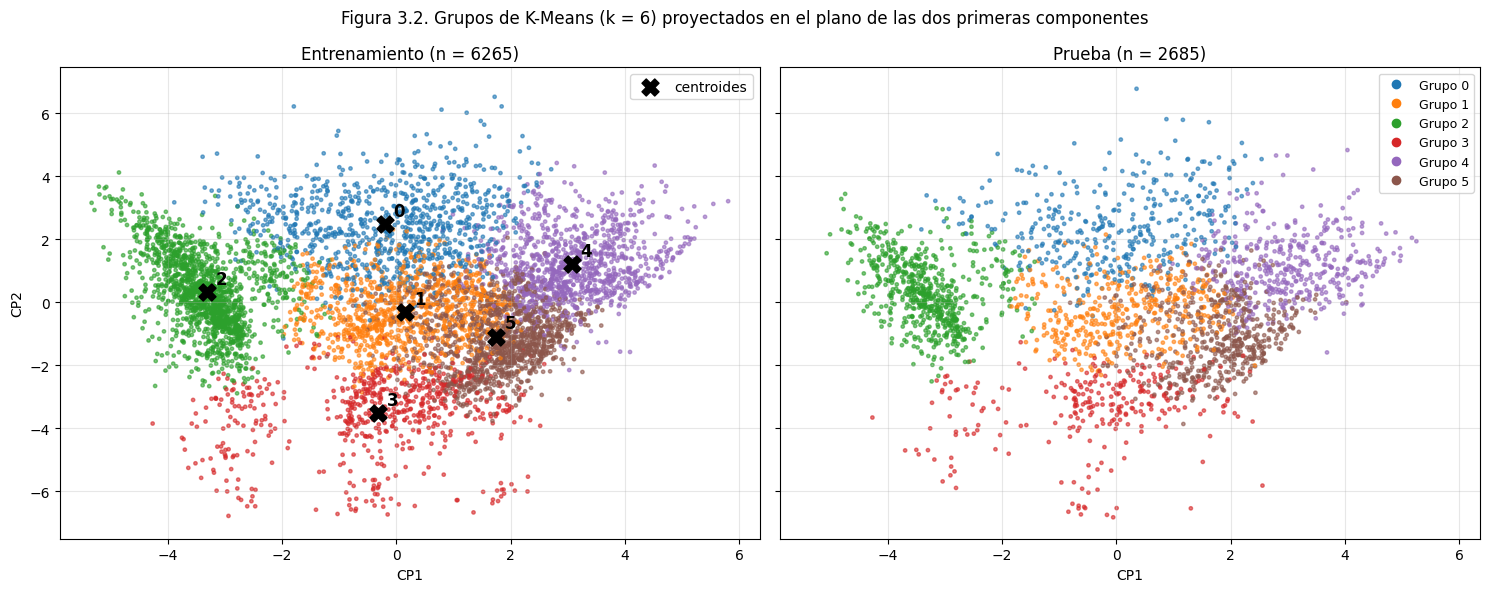

In [16]:
from sklearn.decomposition import PCA

pca_vis = PCA(n_components=2, random_state=SEED).fit(Xs_tr)     # solo para visualizar
P_tr, P_te = pca_vis.transform(Xs_tr), pca_vis.transform(Xs_te)
print("Varianza explicada por el plano (CP1 + CP2):", pca_vis.explained_variance_ratio_.round(3),
      round(pca_vis.explained_variance_ratio_.sum(), 3))
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for a, P, lab, tit in [(ax[0], P_tr, lab_km_tr, "Entrenamiento"), (ax[1], P_te, lab_km_te, "Prueba")]:
    a.scatter(P[:, 0], P[:, 1], c=lab, cmap="tab10", vmin=0, vmax=9, s=6, alpha=0.6)
    a.set_title(f"{tit} (n = {len(P)})"); a.set_xlabel("CP1"); a.grid(alpha=0.3)
ax[0].set_ylabel("CP2")
c2 = pca_vis.transform(km.cluster_centers_)
ax[0].scatter(c2[:, 0], c2[:, 1], c="black", marker="X", s=150, label="centroides")
for g, (x, y) in enumerate(c2):
    ax[0].annotate(str(g), (x, y), xytext=(6, 6), textcoords="offset points", fontsize=12, weight="bold")
handles = [plt.Line2D([], [], marker="o", ls="", color=plt.cm.tab10(g), label=f"Grupo {g}") for g in range(K)]
ax[1].legend(handles=handles, loc="best", fontsize=9)
ax[0].legend(loc="best")
fig.suptitle("Figura 3.2. Grupos de K-Means (k = 6) proyectados en el plano de las dos primeras componentes", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig_3_2_kmeans_pca.png", dpi=150); plt.show()

min_samples = 18 (D + 1) → percentiles 50/80/90/95/98 de la k-distancia: [1.463 1.975 2.444 2.848 3.359]
min_samples = 34 (2 × D) → percentiles 50/80/90/95/98 de la k-distancia: [1.686 2.227 2.752 3.197 3.842]


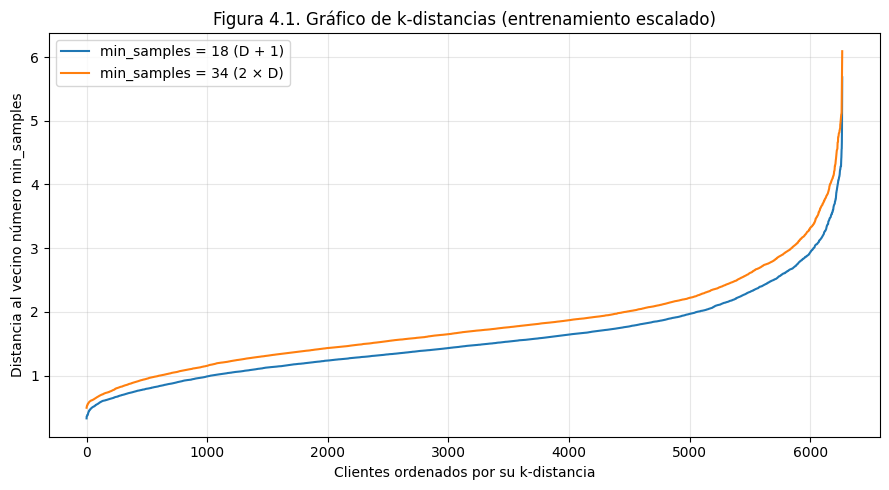

In [17]:
from sklearn.cluster import DBSCAN, HDBSCAN
from sklearn.neighbors import NearestNeighbors

D = Xs_tr.shape[1]
MS_CANDIDATOS = {"D + 1": D + 1, "2 × D": 2 * D}          # reglas prácticas para min_samples (Guía 11)
fig, ax = plt.subplots(figsize=(9, 5))
for nombre, ms in MS_CANDIDATOS.items():
    dist, _ = NearestNeighbors(n_neighbors=ms).fit(Xs_tr).kneighbors(Xs_tr)
    kdist = np.sort(dist[:, -1])
    print(f"min_samples = {ms} ({nombre}) → percentiles 50/80/90/95/98 de la k-distancia:",
          np.percentile(kdist, [50, 80, 90, 95, 98]).round(3))
    ax.plot(kdist, label=f"min_samples = {ms} ({nombre})")
ax.set_xlabel("Clientes ordenados por su k-distancia"); ax.set_ylabel("Distancia al vecino número min_samples")
ax.set_title("Figura 4.1. Gráfico de k-distancias (entrenamiento escalado)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.savefig("figuras/fig_4_1_kdistancias.png", dpi=150); plt.show()

 min_samples  eps  clusters  ruido_%  grupo_1_%  grupo_2_%  silhouette  davies_bouldin  tiempo_s
          18 1.00         8   71.397     14.254      7.582       0.300           0.957     0.111
          18 1.25         8   47.757     30.535     16.504       0.070           1.094     0.075
          18 1.50         3   24.932     74.461      0.319       0.038           1.031     0.110
          18 1.75         1   14.589     85.411      0.000         NaN             NaN     0.112
          18 2.00         2    8.827     90.630      0.543       0.371           0.743     0.118
          18 2.25         3    5.092     93.855      0.798       0.321           0.894     0.131
          18 2.50         2    3.017     95.706      1.277       0.356           0.915     0.156
          18 2.75         1    1.676     98.324      0.000         NaN             NaN     0.171
          18 3.00         1    0.782     99.218      0.000         NaN             NaN     0.204
          34 1.00         3   

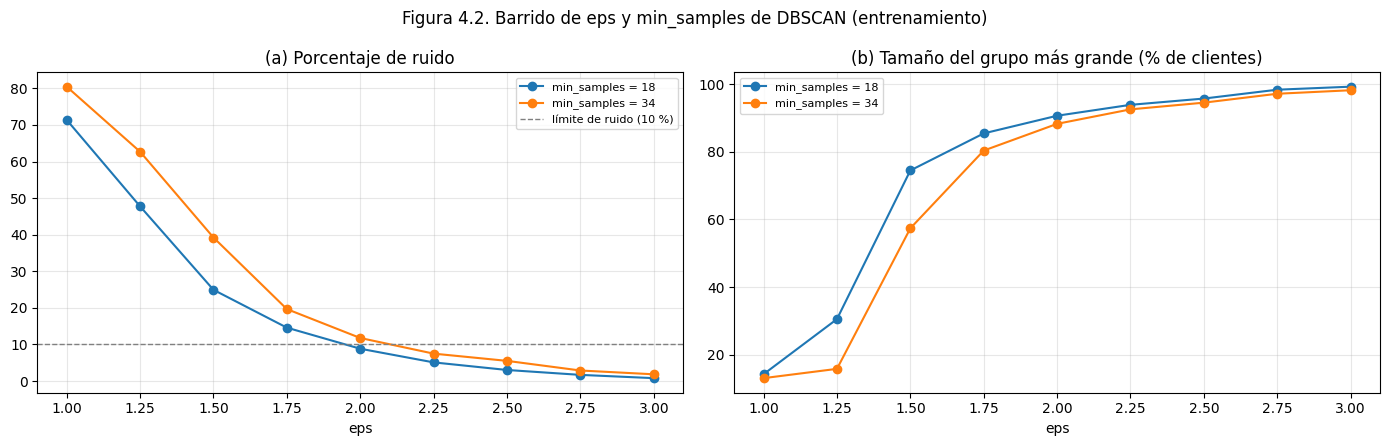

In [18]:
barrido = []
for ms in MS_CANDIDATOS.values():
    for eps in np.arange(1.0, 3.01, 0.25):
        t0 = time.perf_counter()
        lab = DBSCAN(eps=eps, min_samples=ms).fit(Xs_tr).labels_
        t = time.perf_counter() - t0
        m = lab != -1                                       # las métricas internas excluyen el ruido
        n_cl = len(set(lab[m]))
        tam = np.sort(np.bincount(lab[m]))[::-1] / len(lab) * 100 if n_cl else np.array([])
        barrido.append({"min_samples": ms, "eps": round(eps, 2), "clusters": n_cl,
                        "ruido_%": 100 * (~m).mean(),
                        "grupo_1_%": tam[0] if n_cl > 0 else 0, "grupo_2_%": tam[1] if n_cl > 1 else 0,
                        "silhouette": silhouette_score(Xs_tr[m], lab[m]) if n_cl > 1 else np.nan,
                        "davies_bouldin": davies_bouldin_score(Xs_tr[m], lab[m]) if n_cl > 1 else np.nan,
                        "tiempo_s": t})
barrido = pd.DataFrame(barrido)
print(barrido.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for ms, g in barrido.groupby("min_samples"):
    ax[0].plot(g["eps"], g["ruido_%"], "o-", label=f"min_samples = {ms}")
    ax[1].plot(g["eps"], g["grupo_1_%"], "o-", label=f"min_samples = {ms}")
ax[0].axhline(10, color="grey", ls="--", lw=1, label="límite de ruido (10 %)")
ax[0].set_title("(a) Porcentaje de ruido"); ax[1].set_title("(b) Tamaño del grupo más grande (% de clientes)")
for a in ax: a.set_xlabel("eps"); a.grid(alpha=0.3); a.legend(fontsize=8)
fig.suptitle("Figura 4.2. Barrido de eps y min_samples de DBSCAN (entrenamiento)", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig_4_2_barrido_dbscan.png", dpi=150); plt.show()

In [19]:
# Variante jerárquica de DBSCAN: no necesita eps y tolera densidades distintas
hdb = []
for mcs in [50, 100, 200, 300]:
    lab = HDBSCAN(min_cluster_size=mcs, min_samples=10).fit(Xs_tr).labels_
    m = lab != -1; n_cl = len(set(lab[m]))
    tam = np.sort(np.bincount(lab[m]))[::-1] / len(lab) * 100 if n_cl else np.array([])
    hdb.append({"min_cluster_size": mcs, "clusters": n_cl, "ruido_%": 100 * (~m).mean(),
                "tamaños_%": tam.round(1).tolist(),
                "silhouette": silhouette_score(Xs_tr[m], lab[m]) if n_cl > 1 else np.nan})
print(pd.DataFrame(hdb).round(3).to_string(index=False))

 min_cluster_size  clusters  ruido_%    tamaños_%  silhouette
               50         2    8.747  [90.2, 1.0]       0.368
              100         2   48.077 [35.5, 16.5]       0.358
              200         2   48.077 [35.5, 16.5]       0.358
              300         2   48.077 [35.5, 16.5]       0.358


In [20]:
from sklearn.neighbors import KNeighborsClassifier

EPS, MS = 2.5, 18
dbs = DBSCAN(eps=EPS, min_samples=MS)
t0 = time.perf_counter(); dbs.fit(Xs_tr); t_fit_db = time.perf_counter() - t0
lab_db_tr = dbs.labels_
es_nucleo = np.zeros(len(Xs_tr), dtype=bool); es_nucleo[dbs.core_sample_indices_] = True
tipo = np.where(lab_db_tr == -1, "ruido", np.where(es_nucleo, "núcleo", "frontera"))
print(f"Tiempo de entrenamiento: {t_fit_db:.3f} s")
print("Tipo de punto:", pd.Series(tipo).value_counts().to_dict())
print("Clientes por grupo (−1 = ruido):", pd.Series(lab_db_tr).value_counts().sort_index().to_dict())

Tiempo de entrenamiento: 0.388 s
Tipo de punto: {'núcleo': 5695, 'frontera': 381, 'ruido': 189}
Clientes por grupo (−1 = ruido): {-1: 189, 0: 5996, 1: 80}


In [21]:
# DBSCAN no tiene predict(): un k-NN sobre los puntos núcleo asigna la prueba; si el núcleo más cercano
# está a más de eps, el cliente se marca como ruido (Guía 11, Paso 7)
t0 = time.perf_counter()
knn_db = KNeighborsClassifier(n_neighbors=1).fit(dbs.components_, lab_db_tr[dbs.core_sample_indices_])
d_nuc, _ = knn_db.kneighbors(Xs_te, n_neighbors=1)
lab_db_te = knn_db.predict(Xs_te)
lab_db_te[d_nuc[:, 0] > EPS] = -1
t_pred_db = time.perf_counter() - t0
print(f"Tiempo de asignación de la prueba: {1000 * t_pred_db:.1f} ms")

def metricas_db(X, lab):
    m = lab != -1                                           # se excluye el ruido
    n_cl = len(set(lab[m]))
    out = {"clusters": n_cl, "ruido_%": 100 * (~m).mean()}
    if n_cl > 1:
        out.update(metricas(X[m], lab[m]))
    return out

res_db = pd.DataFrame({"entrenamiento": metricas_db(Xs_tr, lab_db_tr), "prueba": metricas_db(Xs_te, lab_db_te)}).T
print(res_db.round(3).to_string())
print("Clientes de prueba por grupo:", pd.Series(lab_db_te).value_counts().sort_index().to_dict())

Tiempo de asignación de la prueba: 266.9 ms
               clusters  ruido_%  silhouette  davies_bouldin  calinski_harabasz
entrenamiento       2.0    3.017       0.356           0.915            253.672
prueba              2.0    2.868       0.357           0.866             92.027
Clientes de prueba por grupo: {-1: 77, 0: 2580, 1: 28}


In [22]:
# Medianas en unidades originales por grupo de DBSCAN (−1 = ruido)
perfil_db = X_tr_imp.assign(grupo=lab_db_tr).groupby("grupo")[VARS_PERFIL].median()
perfil_db.insert(0, "n", pd.Series(lab_db_tr).value_counts().sort_index())
print(perfil_db.round(2).to_string())

# ¿En qué segmentos de K-Means caen el ruido y el grupo pequeño?
print("\nDBSCAN (filas) frente a K-Means (columnas), entrenamiento:")
print(pd.crosstab(lab_db_tr, lab_km_tr, rownames=["DBSCAN"], colnames=["K-Means"]))
print("ARI DBSCAN vs. K-Means (entrenamiento):", round(adjusted_rand_score(lab_km_tr, lab_db_tr), 3))

          n  BALANCE  PURCHASES  ONEOFF_PURCHASES  INSTALLMENTS_PURCHASES  CASH_ADVANCE  PURCHASES_FREQUENCY  CASH_ADVANCE_FREQUENCY  CREDIT_LIMIT  PAYMENTS  PRC_FULL_PAYMENT
grupo                                                                                                                                                                         
-1      189   323.80     264.98             118.2                    0.00        339.49                 0.25                     0.1        3000.0      0.00               0.0
 0     5996   913.20     366.92              39.0                   98.60          0.00                 0.50                     0.0        3000.0    890.26               0.0
 1       80     4.28      49.83               0.0                    4.64          0.00                 0.08                     0.0        3000.0      0.00               0.0

DBSCAN (filas) frente a K-Means (columnas), entrenamiento:
K-Means    0    1     2    3     4     5
DBSCAN                  

In [23]:
rng = np.random.RandomState(SEED)
ari_db, ruido_b = [], []
for b in range(10):
    idx = rng.choice(len(Xs_tr), int(0.8 * len(Xs_tr)), replace=False)
    lab_b = DBSCAN(eps=EPS, min_samples=MS).fit(Xs_tr[idx]).labels_
    ari_db.append(adjusted_rand_score(lab_db_tr[idx], lab_b)); ruido_b.append(100 * (lab_b == -1).mean())
print(f"ARI submuestras: media {np.mean(ari_db):.3f} | mín. {np.min(ari_db):.3f} | "
      f"ruido entre {np.min(ruido_b):.1f} % y {np.max(ruido_b):.1f} %")

ARI submuestras: media 0.939 | mín. 0.924 | ruido entre 3.4 % y 3.9 %


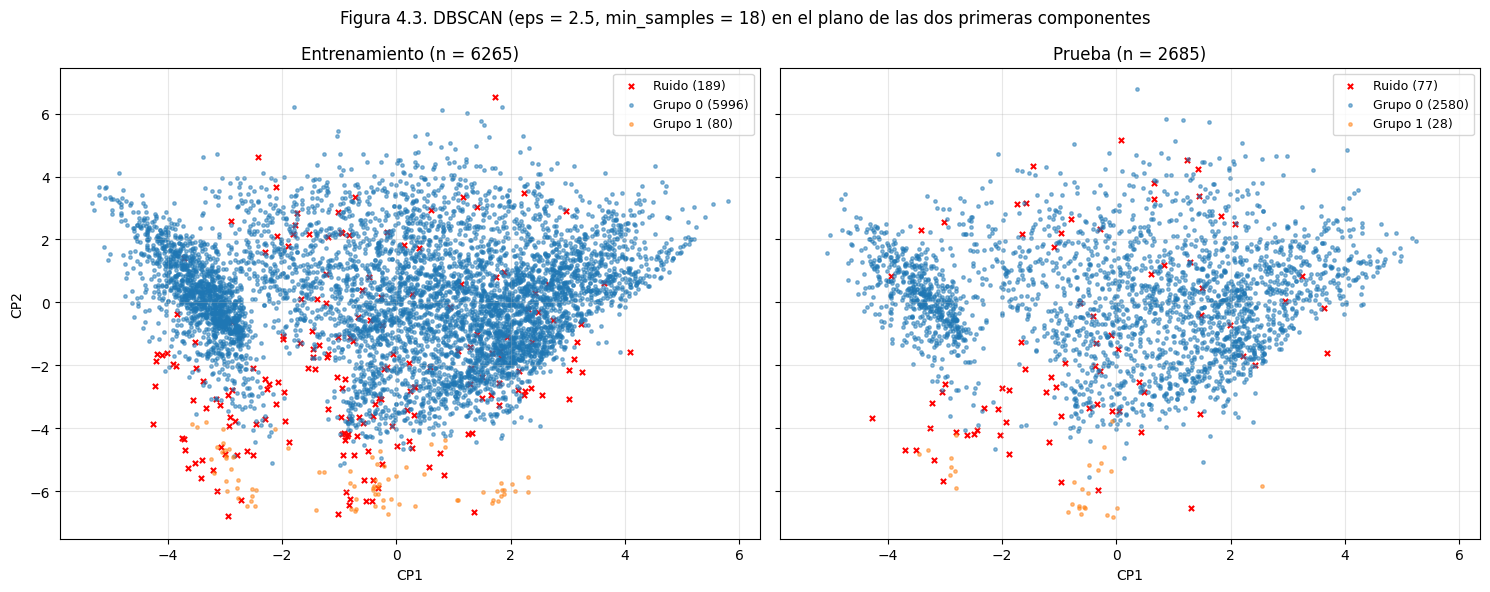

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
for a, P, lab, tit in [(ax[0], P_tr, lab_db_tr, "Entrenamiento"), (ax[1], P_te, lab_db_te, "Prueba")]:
    for g in sorted(set(lab)):
        mk = lab == g
        if g == -1:
            a.scatter(P[mk, 0], P[mk, 1], c="red", marker="x", s=14, label=f"Ruido ({mk.sum()})")
        else:
            a.scatter(P[mk, 0], P[mk, 1], s=6, alpha=0.5, color=plt.cm.tab10(g), label=f"Grupo {g} ({mk.sum()})")
    a.set_title(f"{tit} (n = {len(P)})"); a.set_xlabel("CP1"); a.grid(alpha=0.3); a.legend(fontsize=9)
ax[0].set_ylabel("CP2")
fig.suptitle(f"Figura 4.3. DBSCAN (eps = {EPS}, min_samples = {MS}) en el plano de las dos primeras componentes", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig_4_3_dbscan_pca.png", dpi=150); plt.show()

 componente  autovalor  varianza_%  acumulada_%
          1       5.78       34.01        34.01
          2       3.80       22.32        56.33
          3       1.58        9.28        65.62
          4       1.26        7.39        73.01
          5       1.10        6.48        79.49
          6       0.88        5.19        84.68
          7       0.69        4.06        88.75
          8       0.62        3.64        92.39
          9       0.32        1.87        94.26
         10       0.23        1.37        95.63
         11       0.23        1.36        97.00
         12       0.16        0.94        97.93
         13       0.12        0.73        98.66
         14       0.11        0.64        99.30
         15       0.05        0.27        99.58
         16       0.04        0.25        99.83
         17       0.03        0.17       100.00
Componentes para retener ≥ 80%: 6
Componentes para retener ≥ 90%: 8
Componentes para retener ≥ 95%: 10
Componentes con autovalor > 1 (cr

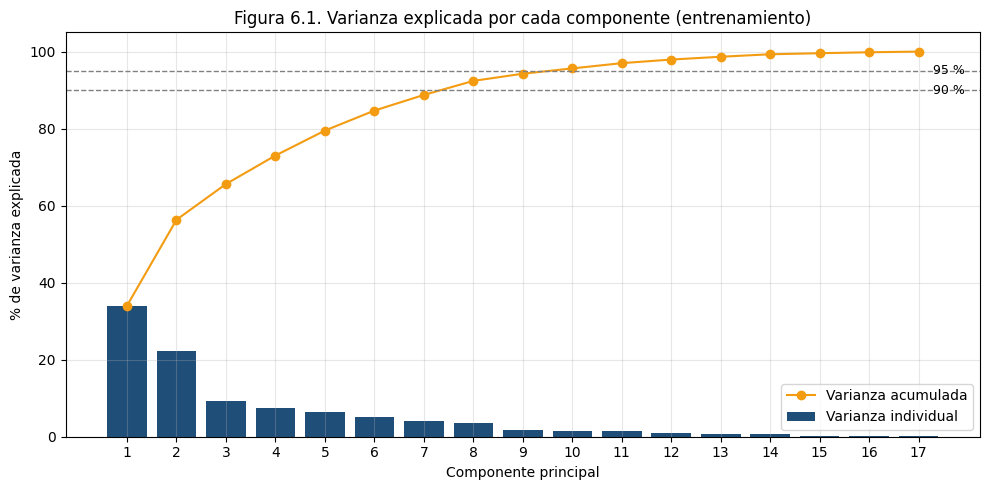

In [25]:
pca_full = PCA(random_state=SEED).fit(Xs_tr)                 # ajustado SOLO con el entrenamiento
var_exp = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var_exp)
tabla_pca = pd.DataFrame({"componente": np.arange(1, len(var_exp) + 1),
                          "autovalor": pca_full.explained_variance_,
                          "varianza_%": 100 * var_exp, "acumulada_%": 100 * var_acum})
print(tabla_pca.round(2).to_string(index=False))
for umbral in (0.80, 0.90, 0.95):
    print(f"Componentes para retener ≥ {umbral:.0%}: {np.argmax(var_acum >= umbral) + 1}")
print("Componentes con autovalor > 1 (criterio de Kaiser):", int((pca_full.explained_variance_ > 1).sum()))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(1, len(var_exp) + 1)
ax.bar(x, 100 * var_exp, color="#1f4e79", label="Varianza individual")
ax.plot(x, 100 * var_acum, "o-", color="#f39c12", label="Varianza acumulada")
for u in (90, 95):
    ax.axhline(u, ls="--", lw=1, color="grey"); ax.text(len(x) + 0.3, u, f"{u} %", va="center", fontsize=9)
ax.set_xticks(x); ax.set_xlabel("Componente principal"); ax.set_ylabel("% de varianza explicada")
ax.set_title("Figura 6.1. Varianza explicada por cada componente (entrenamiento)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figuras/fig_6_1_varianza_pca.png", dpi=150); plt.show()

                                    PC1    PC2    PC3    PC4
BALANCE                          -0.111  0.429 -0.010  0.136
BALANCE_FREQUENCY                 0.027  0.336 -0.158  0.218
PURCHASES                         0.365  0.107  0.104 -0.121
ONEOFF_PURCHASES                  0.213  0.204  0.523 -0.138
INSTALLMENTS_PURCHASES            0.330  0.057 -0.373 -0.085
CASH_ADVANCE                     -0.295  0.249 -0.090 -0.278
PURCHASES_FREQUENCY               0.370  0.101 -0.189 -0.157
ONEOFF_PURCHASES_FREQUENCY        0.223  0.203  0.462 -0.169
PURCHASES_INSTALLMENTS_FREQUENCY  0.316  0.054 -0.451 -0.094
CASH_ADVANCE_FREQUENCY           -0.250  0.268 -0.112 -0.393
CASH_ADVANCE_TRX                 -0.277  0.278 -0.114 -0.347
PURCHASES_TRX                     0.380  0.148 -0.033 -0.135
CREDIT_LIMIT                      0.054  0.244  0.202  0.001
PAYMENTS                          0.052  0.357 -0.013  0.195
MINIMUM_PAYMENTS                 -0.055  0.389 -0.138  0.321
PRC_FULL_PAYMENT        

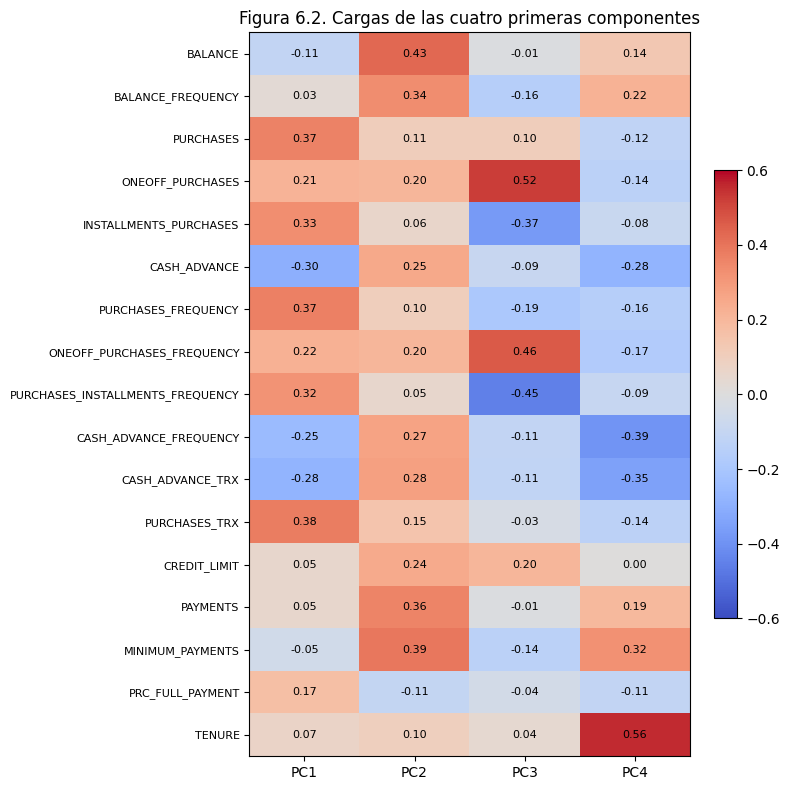

In [26]:
cargas = pd.DataFrame(pca_full.components_[:4].T, index=X_tr_log.columns, columns=["PC1", "PC2", "PC3", "PC4"])
print(cargas.round(3).to_string())
for pc in ["PC1", "PC2", "PC3"]:
    top = cargas[pc].abs().sort_values(ascending=False).head(5).index
    print(f"\n{pc} — variables con mayor carga:", {v: round(float(cargas.loc[v, pc]), 3) for v in top})

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(cargas.values, cmap="coolwarm", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(cargas.columns)
ax.set_yticks(range(len(cargas))); ax.set_yticklabels(cargas.index, fontsize=8)
for i in range(cargas.shape[0]):
    for j in range(cargas.shape[1]):
        ax.text(j, i, f"{cargas.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, fraction=0.046); ax.set_title("Figura 6.2. Cargas de las cuatro primeras componentes")
plt.tight_layout(); plt.savefig("figuras/fig_6_2_cargas_pca.png", dpi=150); plt.show()

                                    PC1    PC2    PC3    PC4
BALANCE                          -0.111  0.429 -0.010  0.136
BALANCE_FREQUENCY                 0.027  0.336 -0.158  0.218
PURCHASES                         0.365  0.107  0.104 -0.121
ONEOFF_PURCHASES                  0.213  0.204  0.523 -0.138
INSTALLMENTS_PURCHASES            0.330  0.057 -0.373 -0.085
CASH_ADVANCE                     -0.295  0.249 -0.090 -0.278
PURCHASES_FREQUENCY               0.370  0.101 -0.189 -0.157
ONEOFF_PURCHASES_FREQUENCY        0.223  0.203  0.462 -0.169
PURCHASES_INSTALLMENTS_FREQUENCY  0.316  0.054 -0.451 -0.094
CASH_ADVANCE_FREQUENCY           -0.250  0.268 -0.112 -0.393
CASH_ADVANCE_TRX                 -0.277  0.278 -0.114 -0.347
PURCHASES_TRX                     0.380  0.148 -0.033 -0.135
CREDIT_LIMIT                      0.054  0.244  0.202  0.001
PAYMENTS                          0.052  0.357 -0.013  0.195
MINIMUM_PAYMENTS                 -0.055  0.389 -0.138  0.321
PRC_FULL_PAYMENT        

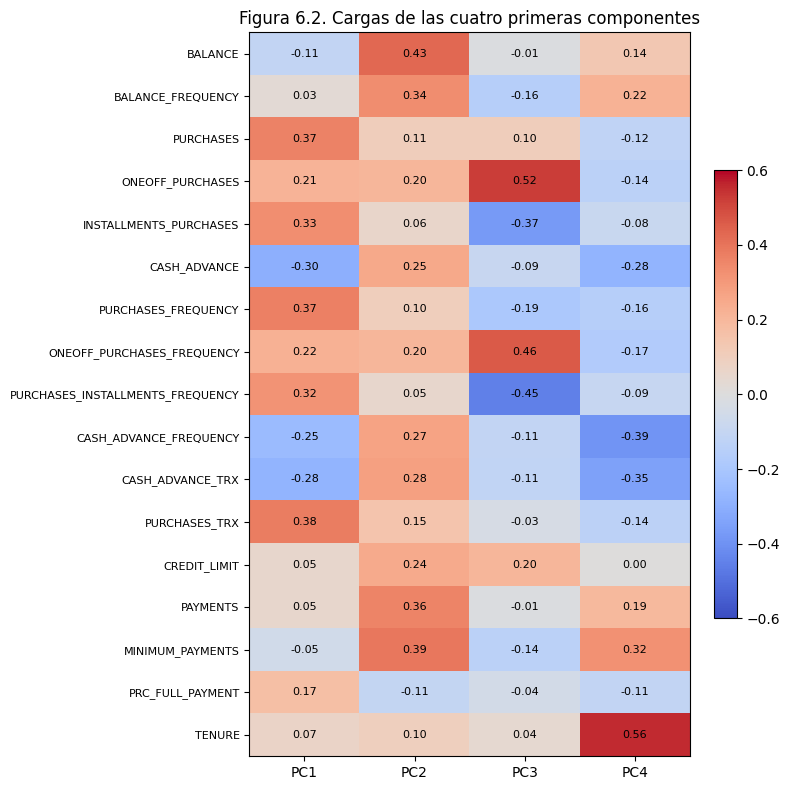

In [27]:
cargas = pd.DataFrame(pca_full.components_[:4].T, index=X_tr_log.columns, columns=["PC1", "PC2", "PC3", "PC4"])
print(cargas.round(3).to_string())
for pc in ["PC1", "PC2", "PC3"]:
    top = cargas[pc].abs().sort_values(ascending=False).head(5).index
    print(f"\n{pc} — variables con mayor carga:", {v: round(float(cargas.loc[v, pc]), 3) for v in top})

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(cargas.values, cmap="coolwarm", vmin=-0.6, vmax=0.6, aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels(cargas.columns)
ax.set_yticks(range(len(cargas))); ax.set_yticklabels(cargas.index, fontsize=8)
for i in range(cargas.shape[0]):
    for j in range(cargas.shape[1]):
        ax.text(j, i, f"{cargas.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, fraction=0.046); ax.set_title("Figura 6.2. Cargas de las cuatro primeras componentes")
plt.tight_layout(); plt.savefig("figuras/fig_6_2_cargas_pca.png", dpi=150); plt.show()

In [28]:
N_COMP = 8
pca = PCA(n_components=N_COMP, random_state=SEED).fit(Xs_tr)     # ajustado SOLO con el entrenamiento
Z_tr, Z_te = pca.transform(Xs_tr), pca.transform(Xs_te)
print("Dimensiones:", Z_tr.shape, Z_te.shape,
      "| varianza retenida:", round(100 * pca.explained_variance_ratio_.sum(), 2), "%")

Dimensiones: (6265, 8) (2685, 8) | varianza retenida: 92.39 %


      inercia  silhouette  davies_bouldin  calinski_harabasz  grupo_min_%  ARI_sub_media  ARI_sub_min  caída_inercia_%
k                                                                                                                     
2   71043.956       0.277           1.400           2411.766       35.435          0.995        0.986              NaN
3   58928.230       0.247           1.577           2097.322       31.221          0.978        0.954           17.054
4   52212.105       0.244           1.554           1846.275       16.632          0.970        0.942           11.397
5   46643.665       0.245           1.458           1736.597       13.424          0.957        0.900           10.665
6   42340.379       0.244           1.323           1657.469       10.583          0.979        0.971            9.226
7   39329.905       0.250           1.298           1566.542        2.953          0.965        0.856            7.110
8   37163.231       0.240           1.331       

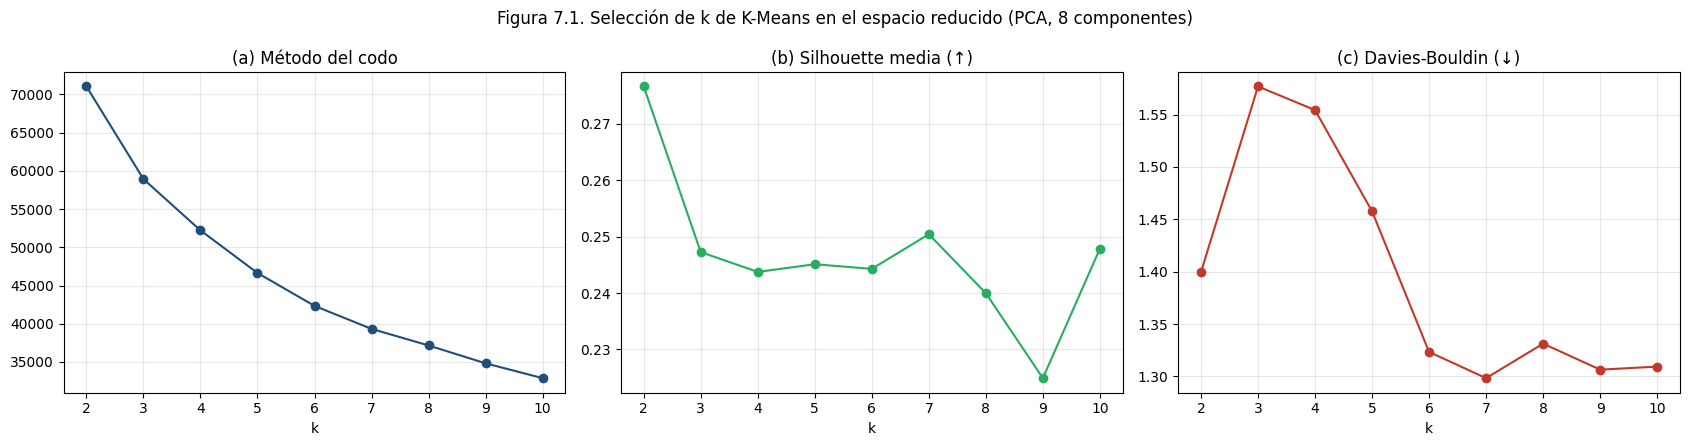

In [29]:
filas_z = []
for k in range(2, 11):
    km_z = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(Z_tr)
    lab = km_z.labels_
    rng = np.random.RandomState(SEED); ari_sub = []
    for b in range(10):                                           # estabilidad con submuestras del 80 %
        idx = rng.choice(len(Z_tr), int(0.8 * len(Z_tr)), replace=False)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Z_tr[idx])
        ari_sub.append(adjusted_rand_score(lab, km_b.predict(Z_tr)))
    filas_z.append({"k": k, "inercia": km_z.inertia_, "silhouette": silhouette_score(Z_tr, lab),
                    "davies_bouldin": davies_bouldin_score(Z_tr, lab),
                    "calinski_harabasz": calinski_harabasz_score(Z_tr, lab),
                    "grupo_min_%": 100 * np.bincount(lab).min() / len(lab),
                    "ARI_sub_media": np.mean(ari_sub), "ARI_sub_min": np.min(ari_sub)})
sel_k_z = pd.DataFrame(filas_z).set_index("k")
sel_k_z["caída_inercia_%"] = -100 * sel_k_z["inercia"].pct_change()
print(sel_k_z.round(3).to_string())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, col, color, tit in [(ax[0], "inercia", "#1f4e79", "(a) Método del codo"),
                           (ax[1], "silhouette", "#27ae60", "(b) Silhouette media (↑)"),
                           (ax[2], "davies_bouldin", "#c0392b", "(c) Davies-Bouldin (↓)")]:
    a.plot(sel_k_z.index, sel_k_z[col], "o-", color=color); a.set_title(tit)
    a.set_xlabel("k"); a.grid(alpha=0.3); a.set_xticks(sel_k_z.index)
fig.suptitle(f"Figura 7.1. Selección de k de K-Means en el espacio reducido (PCA, {N_COMP} componentes)", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig_7_1_seleccion_k_pca.png", dpi=150); plt.show()

min_samples = 9 (D + 1): percentiles 50/80/90/95/98 = [0.974 1.397 1.792 2.104 2.473]
min_samples = 16 (2 × D): percentiles 50/80/90/95/98 = [1.129 1.586 2.042 2.397 2.85 ]
 min_samples  eps  clusters  ruido_%  grupo_1_%  grupo_2_%  silhouette  davies_bouldin
           9 0.75        20   59.808     14.381      8.380       0.136           1.077
           9 1.00        12   28.619     38.468     31.253      -0.071           0.972
           9 1.25         3   15.531     83.751      0.527       0.352           0.674
           9 1.50         6    9.449     89.018      0.575       0.026           1.010
           9 1.75         5    4.661     93.727      1.101       0.229           0.788
           9 2.00         5    1.899     95.706      1.708       0.244           1.065
           9 2.25         1    0.766     99.234      0.000         NaN             NaN
           9 2.50         1    0.399     99.601      0.000         NaN             NaN
           9 2.75         1    0.239     99.

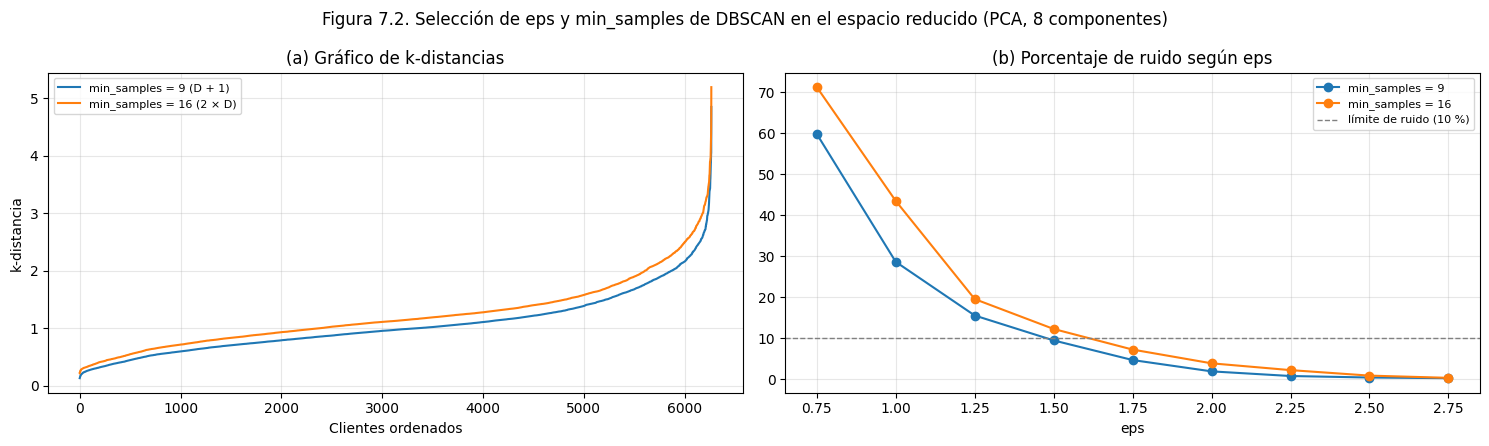

In [30]:
Dz = Z_tr.shape[1]
MS_Z = {"D + 1": Dz + 1, "2 × D": 2 * Dz}                        # ahora D = 8
barrido_z = []
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for nombre, ms in MS_Z.items():
    kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(Z_tr).kneighbors(Z_tr)[0][:, -1])
    print(f"min_samples = {ms} ({nombre}): percentiles 50/80/90/95/98 =", np.percentile(kd, [50, 80, 90, 95, 98]).round(3))
    ax[0].plot(kd, label=f"min_samples = {ms} ({nombre})")
    for eps in np.arange(0.75, 2.76, 0.25):
        lab = DBSCAN(eps=eps, min_samples=ms).fit(Z_tr).labels_
        m = lab != -1; n_cl = len(set(lab[m]))
        tam = np.sort(np.bincount(lab[m]))[::-1] / len(lab) * 100 if n_cl else np.array([])
        barrido_z.append({"min_samples": ms, "eps": round(eps, 2), "clusters": n_cl, "ruido_%": 100 * (~m).mean(),
                          "grupo_1_%": tam[0] if n_cl > 0 else 0, "grupo_2_%": tam[1] if n_cl > 1 else 0,
                          "silhouette": silhouette_score(Z_tr[m], lab[m]) if n_cl > 1 else np.nan,
                          "davies_bouldin": davies_bouldin_score(Z_tr[m], lab[m]) if n_cl > 1 else np.nan})
barrido_z = pd.DataFrame(barrido_z)
print(barrido_z.round(3).to_string(index=False))
for ms, g in barrido_z.groupby("min_samples"):
    ax[1].plot(g["eps"], g["ruido_%"], "o-", label=f"min_samples = {ms}")
ax[1].axhline(10, color="grey", ls="--", lw=1, label="límite de ruido (10 %)")
ax[0].set_title("(a) Gráfico de k-distancias"); ax[0].set_xlabel("Clientes ordenados"); ax[0].set_ylabel("k-distancia")
ax[1].set_title("(b) Porcentaje de ruido según eps"); ax[1].set_xlabel("eps")
for a in ax: a.grid(alpha=0.3); a.legend(fontsize=8)
fig.suptitle(f"Figura 7.2. Selección de eps y min_samples de DBSCAN en el espacio reducido (PCA, {N_COMP} componentes)", fontsize=12)
plt.tight_layout(); plt.savefig("figuras/fig_7_2_dbscan_pca.png", dpi=150); plt.show()

In [31]:
K_Z = 6
km_z = KMeans(n_clusters=K_Z, init="k-means++", n_init=10, random_state=SEED)
t0 = time.perf_counter(); km_z.fit(Z_tr); t_fit_kmz = time.perf_counter() - t0
t0 = time.perf_counter(); lab_kmz_te = km_z.predict(Z_te); t_pred_kmz = time.perf_counter() - t0
lab_kmz_tr = km_z.labels_
print(f"K-Means PCA → entrenamiento: {t_fit_kmz:.3f} s | predicción: {1000 * t_pred_kmz:.1f} ms")
res_kmz = pd.DataFrame({
    "train (espacio PCA)": metricas(Z_tr, lab_kmz_tr), "test (espacio PCA)": metricas(Z_te, lab_kmz_te),
    "train (espacio original)": metricas(Xs_tr, lab_kmz_tr), "test (espacio original)": metricas(Xs_te, lab_kmz_te)}).T
print(res_kmz.round(3).to_string())
print("Tamaños train (%):", (np.bincount(lab_kmz_tr) / len(lab_kmz_tr) * 100).round(1))
print("ARI con K-Means del espacio original → train:", round(adjusted_rand_score(lab_km_tr, lab_kmz_tr), 3),
      "| test:", round(adjusted_rand_score(lab_km_te, lab_kmz_te), 3))
print(pd.crosstab(lab_km_tr, lab_kmz_tr, rownames=["K-Means original"], colnames=["K-Means PCA"]))

K-Means PCA → entrenamiento: 0.209 s | predicción: 3.2 ms
                          silhouette  davies_bouldin  calinski_harabasz
train (espacio PCA)            0.244           1.323           1657.469
test (espacio PCA)             0.247           1.329            714.958
train (espacio original)       0.222           1.439           1421.384
test (espacio original)        0.225           1.446            612.596
Tamaños train (%): [25.4 15.8 19.6 15.3 10.6 13.3]
ARI con K-Means del espacio original → train: 0.935 | test: 0.94
K-Means PCA          0    1     2    3    4    5
K-Means original                                
0                   47    0     3   17    0  798
1                    5    5     7  924   22    0
2                 1537    0     0    0    3    0
3                    0    0     0    1  634    0
4                    0  971     6   19    0   34
5                    0   13  1213    0    4    2


In [32]:
def dbscan_completo(Ztr, Zte, eps, ms):
    """Entrena DBSCAN, asigna la prueba con k-NN sobre los núcleos y devuelve etiquetas y tiempos."""
    t0 = time.perf_counter(); mod = DBSCAN(eps=eps, min_samples=ms).fit(Ztr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter()
    knn = KNeighborsClassifier(n_neighbors=1).fit(mod.components_, mod.labels_[mod.core_sample_indices_])
    d, _ = knn.kneighbors(Zte, n_neighbors=1)
    lab_te = knn.predict(Zte); lab_te[d[:, 0] > eps] = -1
    t_pred = time.perf_counter() - t0
    return mod.labels_, lab_te, t_fit, t_pred

EPS_Z, MS_ZF = 2.0, 16
lab_dbz_tr, lab_dbz_te, t_fit_dbz, t_pred_dbz = dbscan_completo(Z_tr, Z_te, EPS_Z, MS_ZF)
print(f"DBSCAN PCA → entrenamiento: {t_fit_dbz:.3f} s | asignación de la prueba: {1000 * t_pred_dbz:.1f} ms")
res_dbz = pd.DataFrame({
    "train (espacio PCA)": metricas_db(Z_tr, lab_dbz_tr), "test (espacio PCA)": metricas_db(Z_te, lab_dbz_te),
    "train (espacio original)": metricas_db(Xs_tr, lab_dbz_tr), "test (espacio original)": metricas_db(Xs_te, lab_dbz_te)}).T
print(res_dbz.round(3).to_string())
print("Clientes por grupo (train):", pd.Series(lab_dbz_tr).value_counts().sort_index().to_dict())
print("ARI con DBSCAN del espacio original → train:", round(adjusted_rand_score(lab_db_tr, lab_dbz_tr), 3),
      "| test:", round(adjusted_rand_score(lab_db_te, lab_dbz_te), 3))
ruido_ambos = ((lab_db_tr == -1) & (lab_dbz_tr == -1)).sum()
print(f"Ruido en ambos espacios: {ruido_ambos} de {(lab_db_tr == -1).sum()} (original) y {(lab_dbz_tr == -1).sum()} (PCA)")

rng = np.random.RandomState(SEED); ari_dbz = []
for b in range(10):
    idx = rng.choice(len(Z_tr), int(0.8 * len(Z_tr)), replace=False)
    ari_dbz.append(adjusted_rand_score(lab_dbz_tr[idx], DBSCAN(eps=EPS_Z, min_samples=MS_ZF).fit(Z_tr[idx]).labels_))
print(f"Estabilidad DBSCAN PCA (ARI submuestras): media {np.mean(ari_dbz):.3f} | mín. {np.min(ari_dbz):.3f}")

# Control: los MISMOS hiperparámetros del espacio original (eps = 2,5; min_samples = 18) aplicados al espacio PCA
lab_ctrl, _, _, _ = dbscan_completo(Z_tr, Z_te, EPS, MS)
m = lab_ctrl != -1
print(f"\nControl DBSCAN PCA con eps = {EPS}, min_samples = {MS}: grupos = {len(set(lab_ctrl[m]))}, "
      f"ruido = {100 * (~m).mean():.2f} %, tamaños = {np.bincount(lab_ctrl[m]).tolist()}")

DBSCAN PCA → entrenamiento: 0.644 s | asignación de la prueba: 106.8 ms
                          clusters  ruido_%  silhouette  davies_bouldin  calinski_harabasz
train (espacio PCA)            2.0    3.863       0.372           0.849            254.354
test (espacio PCA)             2.0    3.836       0.371           0.778             86.162
train (espacio original)       2.0    3.863       0.357           0.905            237.053
test (espacio original)        2.0    3.836       0.357           0.833             80.311
Clientes por grupo (train): {-1: 242, 0: 5949, 1: 74}
ARI con DBSCAN del espacio original → train: 0.887 | test: 0.837
Ruido en ambos espacios: 183 de 189 (original) y 242 (PCA)
Estabilidad DBSCAN PCA (ARI submuestras): media 0.915 | mín. 0.889

Control DBSCAN PCA con eps = 2.5, min_samples = 18: grupos = 1, ruido = 1.39 %, tamaños = [6178]


In [33]:
def fila(modelo, espacio, hip, lab_tr, X_eval, t_fit, ari):
    m = lab_tr != -1
    n_cl = len(set(lab_tr[m]))
    met = metricas(X_eval[m], lab_tr[m]) if n_cl > 1 else {"silhouette": np.nan, "davies_bouldin": np.nan, "calinski_harabasz": np.nan}
    return {"Modelo": modelo, "Espacio": espacio, "Hiperparámetros": hip, "N.° grupos": n_cl,
            "Silhouette": met["silhouette"], "Davies-Bouldin": met["davies_bouldin"],
            "Calinski-Harabasz": met["calinski_harabasz"], "% ruido": 100 * (~m).mean(),
            "Tiempo (s)": t_fit, "ARI vs. original": ari}

tabla = pd.DataFrame([
    fila("K-Means", "Original (17 var.)", "k = 6", lab_km_tr, Xs_tr, t_fit_km, np.nan),
    fila("K-Means", f"PCA ({N_COMP} comp.)", f"k = {K_Z}", lab_kmz_tr, Z_tr, t_fit_kmz, adjusted_rand_score(lab_km_tr, lab_kmz_tr)),
    fila("K-Means", "PCA → métricas en original", f"k = {K_Z}", lab_kmz_tr, Xs_tr, t_fit_kmz, adjusted_rand_score(lab_km_tr, lab_kmz_tr)),
    fila("DBSCAN", "Original (17 var.)", f"eps = {EPS}, ms = {MS}", lab_db_tr, Xs_tr, t_fit_db, np.nan),
    fila("DBSCAN", f"PCA ({N_COMP} comp.)", f"eps = {EPS_Z}, ms = {MS_ZF}", lab_dbz_tr, Z_tr, t_fit_dbz, adjusted_rand_score(lab_db_tr, lab_dbz_tr)),
    fila("DBSCAN", "PCA → métricas en original", f"eps = {EPS_Z}, ms = {MS_ZF}", lab_dbz_tr, Xs_tr, t_fit_dbz, adjusted_rand_score(lab_db_tr, lab_dbz_tr)),
])
print("Tabla comparativa (entrenamiento):")
print(tabla.round(3).to_string(index=False))

Tabla comparativa (entrenamiento):
 Modelo                    Espacio    Hiperparámetros  N.° grupos  Silhouette  Davies-Bouldin  Calinski-Harabasz  % ruido  Tiempo (s)  ARI vs. original
K-Means         Original (17 var.)              k = 6           6       0.222           1.449           1423.786    0.000       0.911               NaN
K-Means              PCA (8 comp.)              k = 6           6       0.244           1.323           1657.469    0.000       0.209             0.935
K-Means PCA → métricas en original              k = 6           6       0.222           1.439           1421.384    0.000       0.209             0.935
 DBSCAN         Original (17 var.) eps = 2.5, ms = 18           2       0.356           0.915            253.672    3.017       0.388               NaN
 DBSCAN              PCA (8 comp.) eps = 2.0, ms = 16           2       0.372           0.849            254.354    3.863       0.644             0.887
 DBSCAN PCA → métricas en original eps = 2.0, ms = 16

In [34]:
USAR_PCA = True                      # True: K-Means sobre PCA (8 comp.) · False: K-Means en el espacio original
lab_fin_tr, lab_fin_te = (lab_kmz_tr, lab_kmz_te) if USAR_PCA else (lab_km_tr, lab_km_te)
K_FIN = len(np.unique(lab_fin_tr))

def perfil(X_orig, lab):
    g = X_orig.assign(segmento=lab).groupby("segmento")
    p = g.median().T
    extra = pd.DataFrame({
        "n": g.size(), "% clientes": 100 * g.size() / len(lab),
        "% usa adelantos": 100 * g["CASH_ADVANCE"].apply(lambda s: (s > 0).mean()),
        "% sin compras": 100 * g["PURCHASES"].apply(lambda s: (s == 0).mean()),
        "% paga el total (PRC ≥ 0,5)": 100 * g["PRC_FULL_PAYMENT"].apply(lambda s: (s >= 0.5).mean()),
        "% pagó menos que el mínimo": 100 * g.apply(lambda d: (d["PAYMENTS"] < d["MINIMUM_PAYMENTS"]).mean(),
                                                   include_groups=False),
        "uso del límite (saldo / límite, mediana)": g.apply(lambda d: (d["BALANCE"] / d["CREDIT_LIMIT"]).median(),
                                                            include_groups=False)}).T
    return pd.concat([extra, p])

perf_tr = perfil(X_tr_imp, lab_fin_tr)
print("Perfil de los segmentos (entrenamiento; medianas en unidades originales):")
print(perf_tr.round(2).to_string())
print("\nTamaño en la prueba (%):", (np.bincount(lab_fin_te, minlength=K_FIN) / len(lab_fin_te) * 100).round(1))

Perfil de los segmentos (entrenamiento; medianas en unidades originales):
segmento                                        0        1        2        3        4        5
n                                         1589.00   989.00  1229.00   961.00   663.00   834.00
% clientes                                  25.36    15.79    19.62    15.34    10.58    13.31
% usa adelantos                            100.00    12.03     9.11    23.41    23.08   100.00
% sin compras                               84.02     0.00     0.00     0.00    16.89     0.00
% paga el total (PRC ≥ 0,5)                  1.32    30.54    32.79     4.47    17.65     1.08
% pagó menos que el mínimo                  40.97     7.89    20.50    30.91    12.97    34.77
uso del límite (saldo / límite, mediana)     0.64     0.16     0.05     0.30     0.01     0.62
BALANCE                                   1592.97   776.92    97.92   827.66    11.94  2726.13
BALANCE_FREQUENCY                            1.00     1.00     1.00    

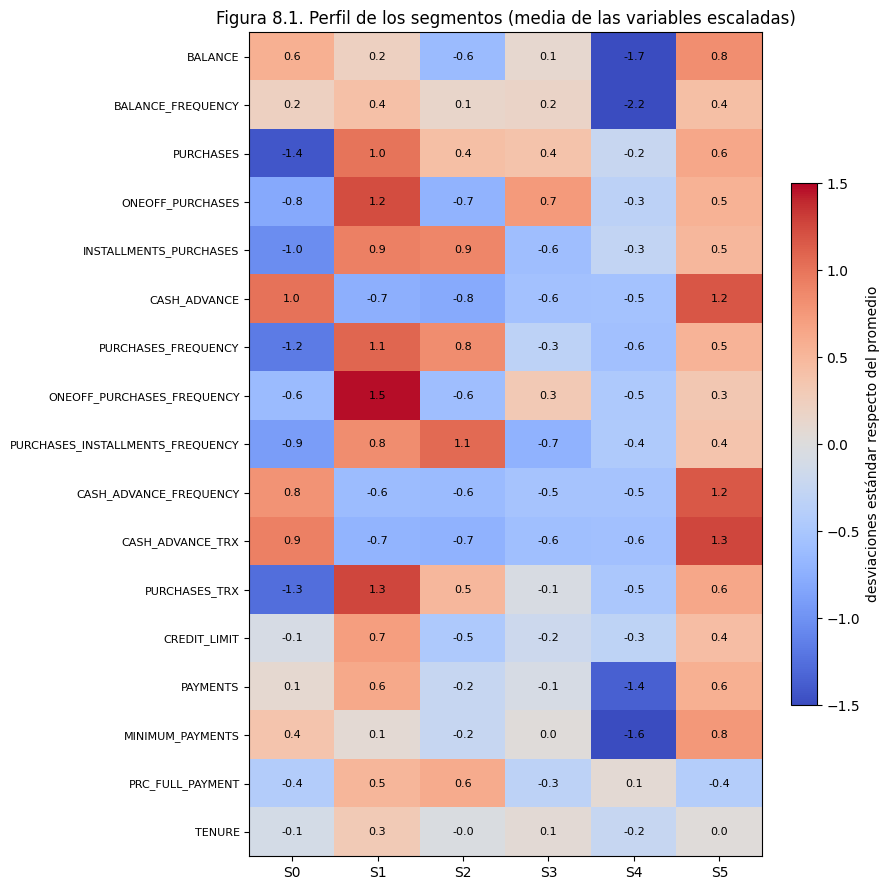

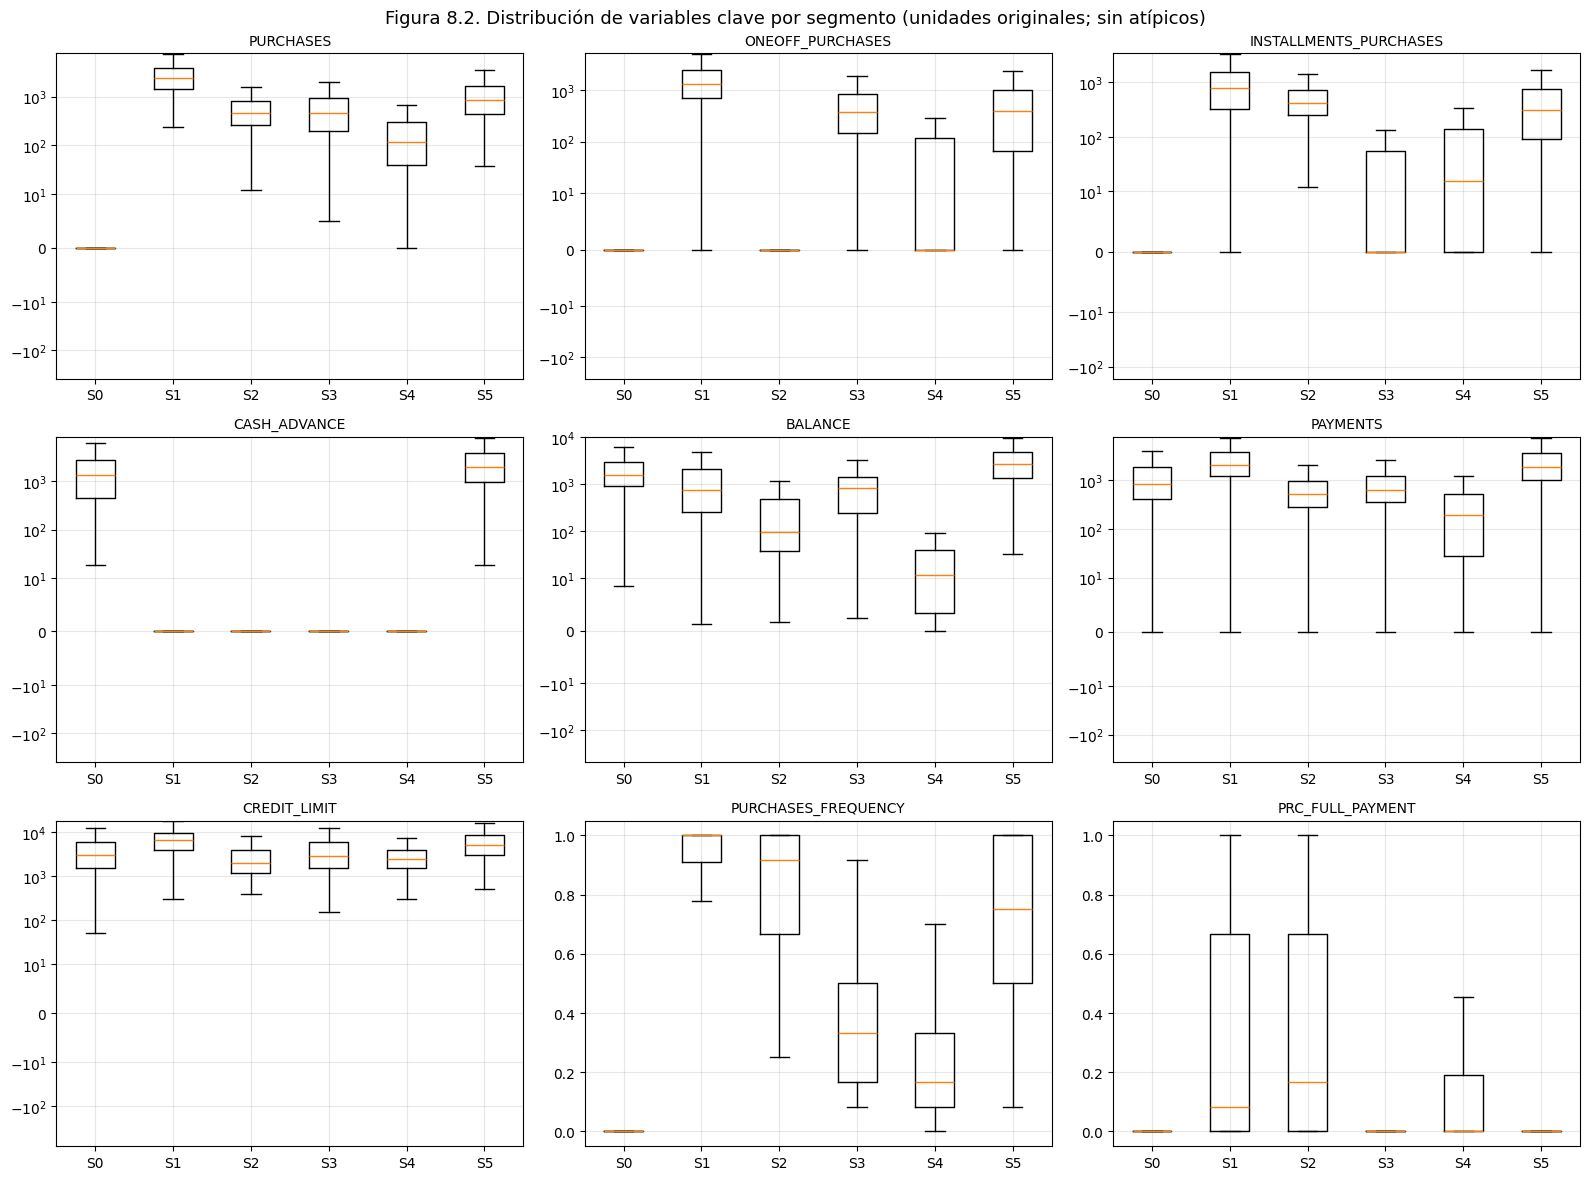

In [35]:
# Perfil estandarizado: media de cada variable escalada por segmento (0 = promedio de la cartera)
z_seg = pd.DataFrame(Xs_tr, columns=X_tr_log.columns).assign(segmento=lab_fin_tr).groupby("segmento").mean().T
fig, ax = plt.subplots(figsize=(9, 9))
im = ax.imshow(z_seg.values, cmap="coolwarm", vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(K_FIN)); ax.set_xticklabels([f"S{g}" for g in z_seg.columns])
ax.set_yticks(range(len(z_seg))); ax.set_yticklabels(z_seg.index, fontsize=8)
for i in range(z_seg.shape[0]):
    for j in range(z_seg.shape[1]):
        ax.text(j, i, f"{z_seg.iloc[i, j]:.1f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, fraction=0.046, label="desviaciones estándar respecto del promedio")
ax.set_title("Figura 8.1. Perfil de los segmentos (media de las variables escaladas)")
plt.tight_layout(); plt.savefig("figuras/fig_8_1_perfil_segmentos.png", dpi=150); plt.show()

VARS_BOX = ["PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "BALANCE", "PAYMENTS",
            "CREDIT_LIMIT", "PURCHASES_FREQUENCY", "PRC_FULL_PAYMENT"]
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.ravel(), VARS_BOX):
    datos = [X_tr_imp[col][lab_fin_tr == g] for g in range(K_FIN)]
    ax.boxplot(datos, showfliers=False)
    ax.set_xticks(range(1, K_FIN + 1)); ax.set_xticklabels([f"S{g}" for g in range(K_FIN)])
    if col in VARS_LOG:
        ax.set_yscale("symlog", linthresh=10)
    ax.set_title(col, fontsize=10); ax.grid(alpha=0.3)
fig.suptitle("Figura 8.2. Distribución de variables clave por segmento (unidades originales; sin atípicos)", fontsize=13)
plt.tight_layout(); plt.savefig("figuras/fig_8_2_boxplots_segmentos.png", dpi=150); plt.show()

t-SNE: 32.3 s | KL final: 1.160


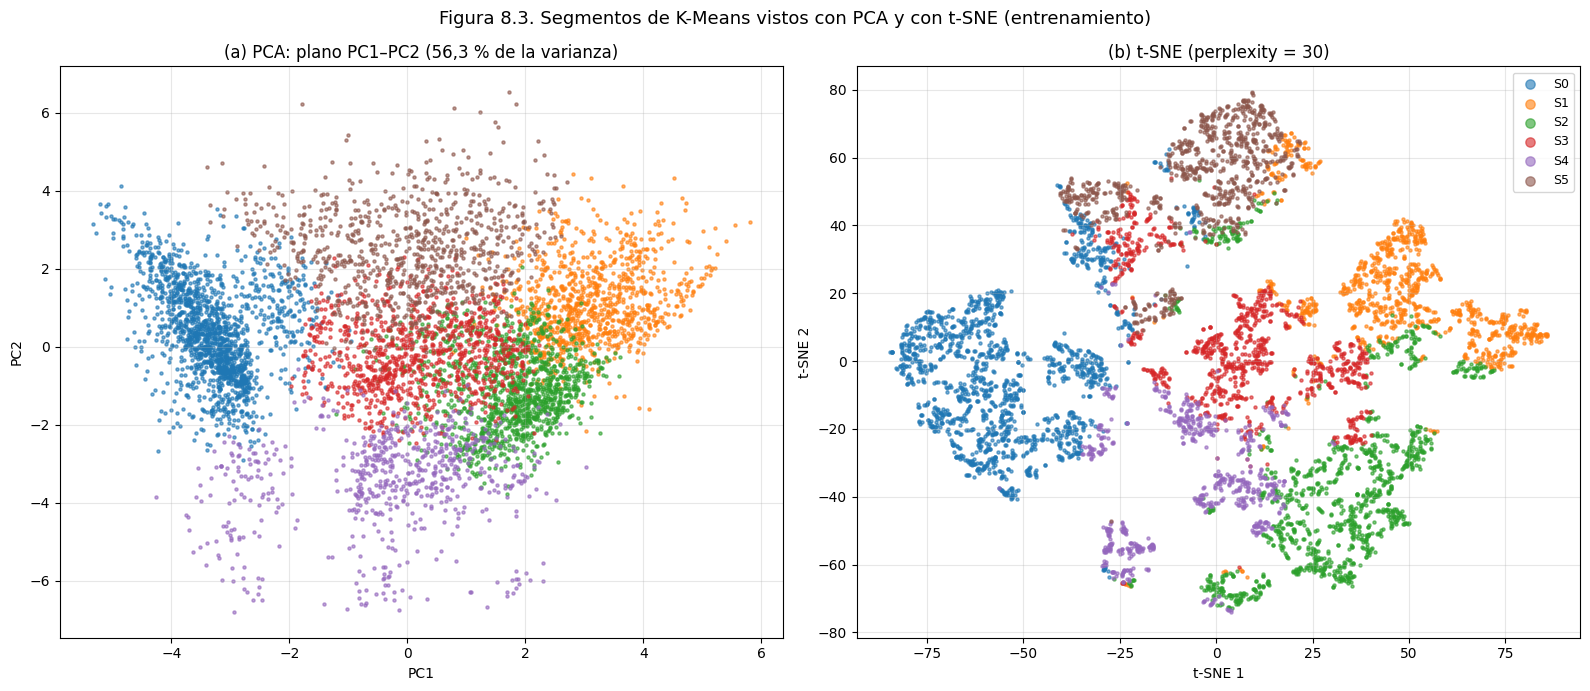

Ruido DBSCAN (PCA) por segmento final: {0: 25, 1: 17, 2: 18, 3: 23, 4: 124, 5: 35}


In [36]:
from sklearn.manifold import TSNE
t0 = time.perf_counter()
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED)
T_tr = tsne.fit_transform(Z_tr)                                      # SOLO para visualizar
print(f"t-SNE: {time.perf_counter() - t0:.1f} s | KL final: {tsne.kl_divergence_:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(16, 7))
for a, P, tit in [(ax[0], P_tr, "(a) PCA: plano PC1–PC2 (56,3 % de la varianza)"), (ax[1], T_tr, "(b) t-SNE (perplexity = 30)")]:
    for g in range(K_FIN):
        mk = lab_fin_tr == g
        a.scatter(P[mk, 0], P[mk, 1], s=5, alpha=0.6, color=plt.cm.tab10(g), label=f"S{g}")
    a.set_title(tit); a.grid(alpha=0.3)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[1].set_xlabel("t-SNE 1"); ax[1].set_ylabel("t-SNE 2")
ax[1].legend(markerscale=3, fontsize=9)
fig.suptitle("Figura 8.3. Segmentos de K-Means vistos con PCA y con t-SNE (entrenamiento)", fontsize=13)
plt.tight_layout(); plt.savefig("figuras/fig_8_3_pca_vs_tsne.png", dpi=150); plt.show()
print("Ruido DBSCAN (PCA) por segmento final:", pd.crosstab(lab_dbz_tr == -1, lab_fin_tr).loc[True].to_dict())

In [37]:
def medir(fn, reps=5):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return np.median(ts)

configs = {
    "K-Means original": (lambda X: KMeans(6, n_init=10, random_state=SEED).fit(X), Xs_tr, Xs_te),
    "K-Means PCA":      (lambda X: KMeans(6, n_init=10, random_state=SEED).fit(X), Z_tr, Z_te),
    "DBSCAN original":  (lambda X: DBSCAN(eps=EPS, min_samples=MS).fit(X), Xs_tr, Xs_te),
    "DBSCAN PCA":       (lambda X: DBSCAN(eps=EPS_Z, min_samples=MS_ZF).fit(X), Z_tr, Z_te),
}
tiempos = []
for nombre, (fit, Xtr, Xte) in configs.items():
    mod = fit(Xtr)
    if nombre.startswith("K-Means"):
        pred = lambda: mod.predict(Xte)
    else:
        knn = KNeighborsClassifier(n_neighbors=1).fit(mod.components_, mod.labels_[mod.core_sample_indices_])
        pred = lambda: knn.kneighbors(Xte, n_neighbors=1)
    fila_t = {"configuración": nombre, "entrenamiento_s": medir(lambda: fit(Xtr)), "predicción_ms": 1000 * medir(pred)}
    # crecimiento: tiempo de entrenamiento con 25 % y 50 % del entrenamiento
    for frac in (0.25, 0.5):
        n = int(frac * len(Xtr))
        fila_t[f"entren_{int(frac*100)}%_s"] = medir(lambda: fit(Xtr[:n]), reps=3)
    tiempos.append(fila_t)
tiempos = pd.DataFrame(tiempos).set_index("configuración")
tiempos["crecimiento_x (50→100 %)"] = tiempos["entrenamiento_s"] / tiempos["entren_50%_s"]
print(tiempos.round(4).to_string())

                  entrenamiento_s  predicción_ms  entren_25%_s  entren_50%_s  crecimiento_x (50→100 %)
configuración                                                                                         
K-Means original           0.0994         0.3526        0.0559        0.0617                    1.6091
K-Means PCA                0.0894         0.1745        0.0318        0.0447                    2.0012
DBSCAN original            0.1336        46.7384        0.0245        0.0487                    2.7427
DBSCAN PCA                 0.5022        22.8738        0.0575        0.1393                    3.6046
